# 02c. 최근 모델은 KV cache를 어떻게 통제하는가 (Part 2 보충)

`02a`와 `02b`는 vLLM이 block을 어떻게 나눠 주고 돌려받는지 봤습니다. 그 규칙들은 모델이 token 하나마다 KV를 얼마나 쌓는지를 주어진 값으로 받습니다. 이 노트북은 그 값 자체를 봅니다. 모델 설계자는 왜 KV를 줄이는 데 매달리는가, 어떤 손잡이를 돌렸는가, 어떤 손잡이가 저장을 줄이고 어떤 손잡이는 연산만 줄이는가. 소재는 DeepSeek V2부터 V4.1-Flash까지, GLM-5부터 GLM-5.3-Flash까지, 그리고 Kimi 계열입니다.

기준 소스는 vLLM v0.32.0(커밋 `5df63a7`)이고, 논문은 arXiv 번호와 절, 그림으로 가리킵니다. 사실에는 근거 ID(`P7-29` 형식)를 붙였습니다.

## 학습 목표

- 긴 문맥 에이전트에서 KV가 왜 병목이 되는지 연산, 저장, 전송으로 나눠 말한다.
- 기법들을 세 곱셈 차원(항목, sequence, 층)에 배치한다.
- MLA와 decoupled RoPE의 식으로 항목 크기를 손으로 계산한다.
- 어떤 기법이 저장을 줄이고 어떤 기법이 연산만 줄이는지 구분한다.
- 압축 꼬리 token에 별도 상태 캐시가 필요한 이유를 말하고 block 내용을 계산한다.
- 층 구성과 record 크기에서 토큰당 global KV를 직접 다시 세어 제작사 값과 대조한다.
- record를 더한 값과 실제 pool의 stride가 왜 다른지 padding으로 설명한다.
- 고정 state, 근사 복원, FP4의 전제 조건, top-k의 한계를 비용으로 말한다.
- 논문의 구조가 vLLM의 어떤 spec으로 표현되는지 코드에서 찾는다.

## 수업 시간표

| 절 | 내용 | 분 |
|---|---|---:|
| 0 | 앞 노트북에서 넘어온 것, 숫자 표기 | 1 |
| 1 | KV가 왜 병목이 되었나, 세대 그림 | 4 |
| 2 | 세 곱셈 차원 | 2 |
| 3 | 항목: MLA, RoPE, 정밀도 | 6 |
| 4 | 연산과 크기는 다르다: DSA, IndexShare | 4 |
| 5 | sequence: CSA, HCA, kpool, 꼬리, block 배치 | 5 |
| 6 | 층: KDA와 sparse 층, CSA2 | 5 |
| 7 | CED와 Hierarchical Sparse Indexer | 3 |
| 8 | 890과 3514.25를 코드로 다시 세기, 실제 stride와 대조 | 5 |
| 9 | 아무도 피하지 못하는 비용 | 5 |
| 10 | GLM-5.3-Flash와 V4.1-Flash 나란히 | 2 |
| 11 | vLLM은 이것을 어떻게 표현하나, 직접 해보기와 정리 | 3 |

## 호출 규모

모델 호출 0회, 유료 API 호출 0회, 키와 GPU가 필요 없습니다. 모든 코드 셀은 수업용 계산 모듈 `vllm_lab.kv_cases`, 저장된 config 스냅샷 `data/model_configs.json`, 저장된 실제 클래스 실행 기록 `data/reference_specs.json`만 읽습니다. 네트워크를 쓰지 않습니다.

## 0. 앞 노트북에서 넘어온 것

`02b` 끝에서 GLM-5.3-Flash는 층의 KV 규칙이 네 가지라 `2*B*L*T*n*d*b` 식으로 용량을 계산할 수 없고, hybrid pool의 padding까지 더하면 실제 점유가 이론식보다 커질 수 있다고 했습니다(P2-61, P2-62). 왜 모델이 그렇게 복잡해졌는지가 이 노트북의 질문입니다.

**숫자 표기.** 이 노트북의 숫자는 모두 아래 다섯 표기 중 하나입니다. 서버를 돌려 관찰한 값은 하나도 없습니다.

| 표기 | 코드의 `kind` | 뜻 |
|---|---|---|
| 제작사 주장 | `reported` | 제작사가 자기 논문이나 문서에 쓴 값입니다. 제3자가 재현한 값이 아닙니다 |
| 우리가 재현 | `reproduced` | config와 코드의 record 크기로 계산했더니 제작사 값과 맞았습니다. 저장 형식은 그 값이 가정한 것입니다 |
| 추정 | `estimate` | 이 자료가 계산한 값입니다. 맞춰 볼 제작사 값이 없거나 식에 넣어 본 결과입니다 |
| 설정값 | 없음 | 모델 `config.json`이나 vLLM 코드에 적힌 값을 그대로 읽은 것입니다 |
| 실제 클래스 실행 | `real_class` | 실제 vLLM 층 클래스와 group 함수를 CPU에서 불러 저장한 값입니다(`data/reference_specs.json`, `docs/reference/specs.md`). 서버를 띄운 값도 메모리를 잰 값도 아닙니다 |

**공식 문서.** vLLM 문서 폴더에서 `tokens_per_state`, `MambaSpec`, `CircularBufferSpec`, `kv_source_layer_ids`, `bounded_replay`를 찾으면 결과가 없습니다. 공식 문서에는 이 설명이 없습니다. 그래서 이 노트북의 순서는 개념, 원문(논문, config, 제작사 문서), 코드, 직접 계산입니다. 예외는 4절의 IndexCache 문서 하나입니다.

`vllm_lab.kv_cases`의 계산 함수는 vLLM이 아니라 수업용 모델입니다. config 값과 코드에 적힌 record 크기를 곱하고 더하는 계산기입니다. 이 계산에는 SWA 캐시, tail ring, hybrid pool padding이 들어가지 않고 각 결과의 `assumptions` 칸에 그렇게 적혀 있습니다. 8절에서 출력합니다. TP 샤딩도 계산에 넣지 않았고 6절의 KDA state 가정에 적혀 있습니다. profiling도 모델링하지 않았습니다. 계산에서 빠진 padding과 block 크기는 `real_`로 시작하는 함수가 저장된 실제 클래스 실행 기록에서 읽어 옵니다. 8절과 9절에서 계산과 나란히 놓습니다.

In [1]:
import json
from math import ceil, lcm

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Rectangle

from vllm_lab import DATA_DIR, VLLM_VERSION, view
from vllm_lab import kv_cases as kv
from vllm_lab.kv_cases import GLM, V4, V41

SNAPSHOT = json.loads((DATA_DIR / "model_configs.json").read_text(encoding="utf-8"))["models"]
FIELDS = {model: entry["fields"] for model, entry in SNAPSHOT.items()}
CONTEXT_1M = FIELDS[V41]["max_position_embeddings"]

print("기준 소스 vLLM", VLLM_VERSION)
view.table([{"model": model, "num_hidden_layers": entry["fields"]["num_hidden_layers"],
             "fetch_date": entry["fetch_date"], "source_url": entry["source_url"]}
            for model, entry in SNAPSHOT.items()])

기준 소스 vLLM 0.32.0


,model,num_hidden_layers,fetch_date,source_url
0,GLM-5.3-Flash,45,2026-11-02,https://huggingface.co/zai-org/GLM-5.3-Flash/raw/main/config.json
1,DeepSeek-V4-Flash,43,2026-11-02,https://huggingface.co/deepseek-ai/DeepSeek-V4-Flash/raw/main/config.json
2,DeepSeek-V4.1-Flash,40,2026-11-02,https://huggingface.co/deepseek-ai/DeepSeek-V4.1-Flash/raw/main/config.json


## 1. KV가 왜 병목이 되었나

오래 일하는 에이전트는 입력이 출력보다 훨씬 많고, 같은 문맥을 턴마다 다시 씁니다. DeepSeek-V4.1-Flash 보고서(arXiv 2609.19969 초록, §1)는 이때의 압박을 세 가지로 나눕니다.

| 압박 | 무엇이 막나 | 어디서 |
|---|---|---|
| 연산 | 새 입력의 prefill이 여전히 비쌉니다 | GPU |
| 저장 | 실행 중의 global KV가 HBM을 채우고, 재사용하려고 남기는 persistent KV가 SSD와 host 메모리를 채웁니다 | HBM, SSD, host DRAM |
| 전송 | cache를 옮기고 읽어 들일 대역폭이 모자랍니다 | I/O, interconnect |

sparse attention으로 긴 문맥의 연산 비용이 먼저 크게 줄었고, 그래서 저장과 이동이 더 두드러진 병목이 되었다는 것이 이 보고서의 진단입니다(제작사 주장, P7-27). [GLM-5.2 글](https://huggingface.co/blog/zai-org/glm-52-blog)도 추론의 주된 병목이 연산에서 KV 용량, 장문 kernel 비용, CPU 쪽 부담으로 옮겨 간다고 씁니다(제작사 주장, P7-39).

요청 하나의 KV에는 두 종류가 있습니다. 문맥 길이에 비례해 커지는 global KV와, 창 크기로 묶이는 SWA KV입니다. 문맥이 충분히 길면 global KV가 실행 중 점유를 지배합니다(같은 보고서 §1). 그래서 세대를 비교하는 지표가 "토큰당 global KV 바이트"입니다. 요청 하나의 global KV는 문맥 token 수에 이 값을 곱한 크기입니다.

**먼저 예측하세요.** 같은 보고서의 그림 1(b)는 세대별 토큰당 global KV를 389,120(V1), 48,068(V3.2), 3,514(V4-Flash), 890(V4.1-Flash) 바이트로 적습니다(제작사 주장, P7-29). 아래 셀을 실행하기 전에 두 가지를 적으세요. (1) 세 번의 세대 전환 중 줄어든 배율이 가장 큰 곳은 어디입니까? (2) 1M token 문맥 요청 하나라면 V1과 V4.1-Flash는 각각 몇 GiB입니까?

,model,kind,bytes_per_token,shrink_from_previous,GiB_at_1M_context
0,DeepSeek-V1,reported,389120,-,380.00
1,DeepSeek-V3.2,reported,48068,8.1,46.94
2,DeepSeek-V4-Flash,reported,3514,13.7,3.43
3,DeepSeek-V4.1-Flash,reported,890,3.9,0.87


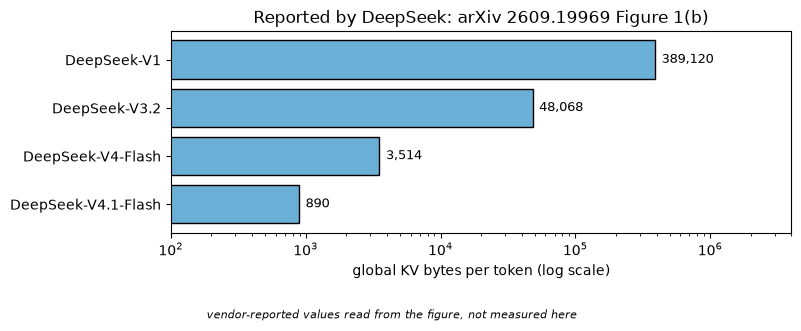

In [2]:
rows, previous = [], None
for row in kv.reported_figures():
    value = row["bytes_per_token"]
    rows.append({"model": row["model"], "kind": row["kind"], "bytes_per_token": value,
                 "shrink_from_previous": round(previous / value, 1) if previous else "-",
                 "GiB_at_1M_context": round(value * CONTEXT_1M / 2**30, 2)})
    previous = value
display(view.table(rows))

figure, axis = plt.subplots(figsize=(8.5, 3.3))
axis.barh([r["model"] for r in rows], [r["bytes_per_token"] for r in rows], color="#6baed6", edgecolor="black")
axis.set_xscale("log")
axis.set_xlim(100, 4_000_000)
axis.invert_yaxis()
for y, r in enumerate(rows):
    axis.text(r["bytes_per_token"] * 1.12, y, f"{r['bytes_per_token']:,}", va="center", fontsize=9)
axis.set_xlabel("global KV bytes per token (log scale)")
axis.set_title("Reported by DeepSeek: arXiv 2609.19969 Figure 1(b)")
figure.text(0.5, 0.01, "vendor-reported values read from the figure, not measured here", ha="center", fontsize=8, style="italic")
figure.subplots_adjust(left=0.24, bottom=0.27, right=0.97)
plt.close(figure)
figure

**관찰할 것.** `shrink_from_previous` 칸에서 가장 큰 값이 있는 행을 찾아 예측과 비교하세요. `GiB_at_1M_context` 칸에서 맨 위 행과 맨 아래 행을 비교하세요. 그림의 x축이 로그라는 점도 확인하세요. 칸 하나의 길이가 곱셈 한 번입니다.

읽을 때 세 가지를 조심합니다.

- `bytes_per_token`은 그림 이미지에서 읽은 제작사 값입니다. 텍스트로 있는 문장은 V4-Flash 대비 약 4배, V1 대비 437배입니다(P7-29).
- `GiB_at_1M_context`는 우리가 곱한 값(추정)입니다. 세대를 같은 잣대에 놓으려는 산수이고, 그 문맥으로 서버를 돌린 결과가 아닙니다.
- 세대마다 파라미터와 층 수가 다릅니다. 한 모델을 압축해 간 기록이 아니므로 배율 하나를 특정 기법의 효과로 읽지 않습니다.

**왜 이렇게 설계했나.** 보고서는 V4.1-Flash의 목표 자체를 KV 압축이라고 제목에 적고, 그 이유를 저장과 전송 병목이 배포 비용을 정한다는 데서 찾습니다(arXiv 2609.19969 §1, 제작사 주장).

## 2. 세 곱셈 차원

V4.1-Flash 보고서 §2.3은 긴 문맥의 저장과 연산을 줄이는 방법을 서로 곱해지는 세 차원으로 정리합니다(P7-01, P7-02). 토큰당 global KV를 식으로 쓰면 왜 곱해지는지 보입니다.

```text
토큰당 global KV = 캐시를 가진 층마다 (record 바이트 / record 하나가 덮는 token 수)를 더한 값
```

| 차원 | 식에서 줄이는 것 | 기법 | 다룰 절 |
|---|---|---|---|
| 항목(entry) | record 바이트 | GQA, MLA, decoupled RoPE, NoPE, FP8, FP4 | 3 |
| sequence | record 하나가 덮는 token 수를 늘림 | CSA, HCA, CSA2의 압축률, kpool(indexer K에만) | 5 |
| 층 | 캐시를 가진 층 수 | 층을 KDA로 바꾸기, CSA2의 cache 공유 | 6 |

표에 없는 것도 있습니다. DSA의 top-k, IndexShare, IndexCache, CED의 목적은 연산 절감이고 main KV 항은 줄이지 않습니다. 건너뛰는 층의 indexer K가 함께 빠지는 작은 몫은 4절에서 봅니다. 이 구분이 4절과 7절의 주제입니다. Single-Pass mHC가 줄이는 활성 메모리 트래픽도 KV 크기와는 무관합니다(제작사 주장, P7-26).

**왜 이렇게 설계했나.** 보고서는 앞선 층 차원 연구(IndexCache, YOIO, HySparse)를 들며 인덱스 재사용만으로는 main KV 저장이 줄지 않고, 세 차원을 모두 다루는 방법은 없었다는 것을 CSA2의 동기로 씁니다(P7-03).

## 3. 항목: MLA, RoPE, 정밀도

### MLA

일반 multi-head attention은 token 하나, 층 하나마다 head별 K와 V를 저장합니다. 그래서 토큰당 원소 수가 `2 n_h d_h l`입니다(`n_h` head 수, `d_h` head 차원, `l` 층 수). MLA는 은닉 상태를 작은 잠재 벡터 `c_t^KV`(차원 `d_c`) 하나로 내려 그것만 저장합니다. K와 V는 이 벡터에서 올려 만드는데, 올리는 행렬이 query와 출력 투영에 흡수되므로 추론 때 K와 V를 실제로 만들 필요가 없습니다(arXiv 2405.04434 §2.1.2, 식 9~11, P7-04).

**먼저 예측하세요.** DeepSeek-V2의 설정값은 층 60, head 128, `d_h` 128, `d_c` 512, `d_h^R` 64입니다(P7-07). MLA의 원소 수는 `(d_c + d_h^R) l`입니다(`d_h^R`이 무엇인지는 곧 봅니다). 실행 전에 두 가지를 적으세요. MLA는 같은 크기의 MHA 대비 몇 퍼센트입니까? 같은 원소 수의 GQA라면 그룹이 몇 개입니까(`2 n_g d_h l`)?

In [3]:
LAYERS_V2, N_H, D_H, D_C, D_H_R = 60, 128, 128, 512, 64  # 설정값: arXiv 2405.04434 §3.1.2

mha = 2 * N_H * D_H * LAYERS_V2
mla = (D_C + D_H_R) * LAYERS_V2
mqa = 2 * D_H * LAYERS_V2
groups = mla / (2 * D_H * LAYERS_V2)
view.table([{"mechanism": name, "elements_per_token": value, "share_of_mha_percent": round(100 * value / mha, 2), "kind": "estimate"}
            for name, value in (("MHA", mha), ("MQA", mqa), (f"GQA with {groups} groups", mla), ("MLA", mla))])

,mechanism,elements_per_token,share_of_mha_percent,kind
0,MHA,1966080,100.00,estimate
1,MQA,15360,0.78,estimate
2,GQA with 2.25 groups,34560,1.76,estimate
3,MLA,34560,1.76,estimate


**관찰할 것.** `share_of_mha_percent` 칸의 MLA 행과, `mechanism` 칸에 찍힌 GQA 그룹 수를 예측과 비교하세요. `elements_per_token`의 단위는 저장 정밀도와 무관한 원소 개수입니다(arXiv 2405.04434 표 1, P7-06). 이 표의 값은 식에 설정값을 넣은 추정입니다.

V2 논문의 "KV cache 93.3% 감소"는 이 표와 기준이 다릅니다. 기준이 같은 크기의 MHA가 아니라 DeepSeek 67B입니다(제작사 주장, P7-08). 두 숫자를 맞춰 보려 하지 않습니다.

MLA는 공짜가 아닙니다. GLM-5 논문(arXiv 2602.15763 §2.1)은 Muon 최적화기로 학습하면 576차원 MLA가 GQA-8의 품질을 따라가지 못해 Muon Split을 도입했다고 씁니다(제작사 주장, P7-32). 576은 512 + 64로 위 식의 `d_c + d_h^R`과 같은 합입니다. 같은 논문의 MLA-256은 decode 연산을 줄이는 변경이고, 논문은 이것이 KV 크기를 바꾼다고 쓰지 않습니다(P7-33).

### decoupled RoPE, 그리고 왜 NoPE가 0을 만드는가

RoPE는 위치에 민감합니다. K의 올리는 행렬 앞에 RoPE를 끼우면 그 행렬이 query 쪽에 흡수되지 못합니다. 현재 token에 달린 RoPE 행렬이 사이에 끼고 행렬곱은 교환되지 않기 때문입니다. 그러면 prefix의 모든 K를 매번 다시 계산해야 합니다. V2의 해법이 decoupled RoPE입니다. RoPE를 싣는 별도 query와 공유 key(차원 `d_h^R`)를 두고 이 key를 함께 저장합니다. 그래서 식이 `(d_c + d_h^R) l`이 됩니다(arXiv 2405.04434 §2.1.3, P7-05). vLLM에서는 `kv_lora_rank + qk_rope_head_dim`이 곧 `head_size`([`mla_attention.py:479`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/mla_attention.py#L479))입니다.

config를 보면 모델마다 이 자리가 다릅니다.

In [4]:
rope_rows = [
    {"model": "DeepSeek-V2", "latent_elements": 512, "rope_elements": 64, "note": "separate shared key"},
    {"model": "GLM-5.3", "latent_elements": 512, "rope_elements": 64, "note": "separate shared key"},
    {"model": GLM, "latent_elements": FIELDS[GLM]["kv_lora_rank"], "rope_elements": FIELDS[GLM]["qk_rope_head_dim"],
     "note": f"mla_use_nope={FIELDS[GLM]['mla_use_nope']}"},
    {"model": V4, "latent_elements": FIELDS[V4]["head_dim"], "rope_elements": 0,
     "note": f"last {FIELDS[V4]['qk_rope_head_dim']} of the latent carry RoPE"},
    {"model": V41, "latent_elements": FIELDS[V41]["head_dim"], "rope_elements": 0,
     "note": f"last {FIELDS[V41]['qk_rope_head_dim']} of the latent carry RoPE"},
]
frame = view.table(rope_rows)
frame["entry_elements"] = frame["latent_elements"] + frame["rope_elements"]
frame[["model", "latent_elements", "rope_elements", "entry_elements", "note"]]

,model,latent_elements,rope_elements,entry_elements,note
0,DeepSeek-V2,512,64,576,separate shared key
1,GLM-5.3,512,64,576,separate shared key
2,GLM-5.3-Flash,512,0,512,mla_use_nope=True
3,DeepSeek-V4-Flash,512,0,512,last 64 of the latent carry RoPE
4,DeepSeek-V4.1-Flash,512,0,512,last 64 of the latent carry RoPE


**관찰할 것.** `entry_elements` 칸에서 GLM-5.3과 GLM-5.3-Flash 행을 비교하세요. 값은 모두 설정값이고 합만 우리가 더했습니다(P7-07, P7-16, P7-40, P7-42). V4 계열은 512 안의 마지막 64차원에 RoPE를 싣습니다(`note` 칸, arXiv 2606.19348 §2.3.3).

GLM-5.3-Flash는 `qk_rope_head_dim`이 0이고 `mla_use_nope`가 참입니다. FLASHMLA_SPARSE 주석([`flashmla_sparse.py:220`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashmla_sparse.py#L220))도 이 조합을 적고, 그 경우 `head_size`는 512입니다. 층마다 64원소가 사라지는 효과입니다.

**왜 이렇게 설계했나.** GLM-5.3-Flash가 RoPE를 뺀 이유를 Z.ai 문서에서 찾지 못했고, 이 모델의 전용 보고서도 찾지 못했습니다(P7-48, 미확인). 같은 구조의 Kimi K3 보고서 §2.1은 사이의 KDA 층이 위치와 최근성을 맡고 MLA 층은 내용 기반 전역 상호작용을 맡으며, 문맥을 늘릴 때 위치 인코딩을 다시 조정하지 않아도 된다고 씁니다(P7-52). 이 이유가 GLM에도 그대로 적용된다는 것은 수업의 해석입니다.

### 정밀도: BF16, FP8, FP4

같은 원소 수라도 저장 형식이 바이트를 정합니다. 코드의 record 크기를 직접 더해 봅니다. `data_bytes`는 값, `scale_bytes`는 양자화 scale입니다. 모두 코드의 주석과 식에서 읽은 설정값입니다.

In [5]:
records = [
    {"format": "bf16 plain, latent 512, rope 0", "used_for": "GLM main at BF16", "data_bytes": 512 * 2, "scale_bytes": 0},
    {"format": "fp8_ds_mla, V4 record", "used_for": "V4 main; V4.1 SWA off SM100", "data_bytes": 448 + 128, "scale_bytes": 8},
    {"format": "fp8_ds_mla, V4.1 record", "used_for": "V4.1 on SM100", "data_bytes": 512, "scale_bytes": 16},
    {"format": "nvfp4_ds_mla", "used_for": "V4.1 compressed main", "data_bytes": 512 // 2, "scale_bytes": 512 // 16},
    {"format": "fp8 indexer", "used_for": "indexer K, auto", "data_bytes": 128, "scale_bytes": 128 // 128 * 4},
    {"format": "mxfp4 indexer", "used_for": "indexer K, opt-in, SM10x or gfx950", "data_bytes": 128 // 2, "scale_bytes": 128 // 32},
]
frame = view.table(records)
frame["record_bytes"] = frame["data_bytes"] + frame["scale_bytes"]
frame

,format,used_for,data_bytes,scale_bytes,record_bytes
0,"bf16 plain, latent 512, rope 0",GLM main at BF16,1024,0,1024
1,"fp8_ds_mla, V4 record",V4 main; V4.1 SWA off SM100,576,8,584
2,"fp8_ds_mla, V4.1 record",V4.1 on SM100,512,16,528
3,nvfp4_ds_mla,V4.1 compressed main,256,32,288
4,fp8 indexer,"indexer K, auto",128,4,132
5,mxfp4 indexer,"indexer K, opt-in, SM10x or gfx950",64,4,68


**관찰할 것.** `record_bytes` 칸에서 `fp8_ds_mla, V4 record`와 `nvfp4_ds_mla` 행의 비를 계산하세요. 제작사가 "거의 반"이라고 적은 값입니다(제작사 주장, P7-25). 근거 코드는 V4 record 주석([`deepseek_v4/attention.py:876`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L876)), `_use_v41_mxfp8_kv_record`([`deepseek_v41/attention.py:128`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L128)) 위의 주석, `compressed_bytes_per_token`([`deepseek_v41/attention.py:516`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L516)), `DSA_INDEXER_KV_DTYPES`([`indexer.py:56`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/indexer.py#L56))입니다.

FP4를 "빠른 KV"로 읽으면 틀립니다. 어디에 쓰느냐에 따라 줄이는 것이 다릅니다.

| 어디의 FP4 | 줄이는 것 | 줄이지 않는 것 | 근거 |
|---|---|---|---|
| V4.1 main KV | HBM과 SSD의 저장 | attention 행렬곱. attention 전에 역양자화합니다 | arXiv 2609.19969 §2.4.4, P7-25 |
| V4 indexer Q와 K | indexer 캐시 크기, 점수 계산 시간. 캐시, 읽기, 곱셈을 모두 FP4로 합니다 | main KV 저장 | arXiv 2606.19348 §2.3.4, §5.2.1, P7-16 |
| SWA KV | 해당 없음. 양자화에 민감해 FP8로 남겨 둡니다 | SWA 저장 | arXiv 2609.19969 §2.4.4, P7-25 |

**왜 이렇게 설계했나.** 보고서 §2.4.4는 main KV에서 FP4의 역할을 행렬곱 가속이 아니라 저장 절감으로 정의합니다. 역양자화한 뒤 attention을 하므로, 그 형식의 행렬곱을 지원하지 않는 하드웨어에서도 더 정확한 형식을 쓸 수 있다는 것이 이유입니다(제작사 주장).

## 4. 연산과 크기는 다르다: DSA, IndexShare

### DSA의 lightning indexer

MLA까지는 query가 앞선 모든 항목을 읽습니다. DSA는 그 앞에 가벼운 lightning indexer를 둡니다. 질의 token과 앞선 token 사이의 색인 점수를 계산하고, 상위 k개의 KV 항목만 읽어 attention을 합니다(DeepSeek-V3.2-Exp 보고서 §1 식 1~2, P7-09). 보고서는 핵심 attention 복잡도가 `O(L^2)`에서 `O(Lk)`로 줄고, indexer 자체는 여전히 `O(L^2)`이지만 MLA보다 훨씬 가볍다고 씁니다(P7-10). 코드에서 k는 `topk_tokens`([`deepseek_v2.py:697`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/deepseek_v2.py#L697))입니다. GLM-5 논문(arXiv 2602.15763 §2.1.1)은 긴 시퀀스에서 attention 연산이 대략 1.5~2배 준다고 쓰고, KV 크기 감소에 대한 수치는 내지 않습니다(제작사 주장, P7-34).

여기서 흔히 틀립니다. 질의마다 k개만 **읽는다**고 k개만 **저장**해도 되는 것은 아닙니다. 다음 질의가 어떤 항목을 고를지 미리 모르기 때문입니다. 오히려 indexer가 쓰는 K를 위한 캐시가 따로 더 생깁니다. `DeepseekV32IndexerCache`([`deepseek_v2.py:638`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/deepseek_v2.py#L638))가 그 층입니다(P7-11, P7-12).

In [6]:
# 실패 재현: 읽는 양을 저장량으로 착각한 계산
TOP_K = FIELDS[V41]["index_topk"]
RECORD = 288  # V4.1 main record, 설정값
CONTEXT = CONTEXT_1M

wrong_bytes = TOP_K * RECORD        # 틀린 계산: top-k만 저장한다고 본다
right_bytes = CONTEXT * RECORD      # 맞는 계산: 압축률 1인 층 하나는 모든 token의 항목을 들고 있어야 한다
view.table([{"calculation": "wrong: stored = top_k x record", "bytes_one_layer": wrong_bytes, "kind": "estimate"},
            {"calculation": "right: stored = context x record", "bytes_one_layer": right_bytes, "kind": "estimate"},
            {"calculation": "what top_k does bound: read per query", "bytes_one_layer": wrong_bytes, "kind": "estimate"}])

,calculation,bytes_one_layer,kind
0,wrong: stored = top_k x record,147456,estimate
1,right: stored = context x record,301989888,estimate
2,what top_k does bound: read per query,147456,estimate


**관찰할 것.** `bytes_one_layer` 칸에서 틀린 행과 맞는 행이 몇 배 차이 나는지 계산하세요. 첫 행과 셋째 행의 값이 같은 이유도 말해 보세요. 같은 값이 저장량으로는 틀리고 질의당 읽는 양으로는 맞습니다.

### IndexShare와 IndexCache

[GLM-5.2 글](https://huggingface.co/blog/zai-org/glm-52-blog)의 IndexShare는 이 구분을 가장 깔끔하게 보여 줍니다. 4개 층마다 indexer 하나를 공유합니다. indexer는 첫 층에 두고, 그 top-k를 4개 층이 씁니다. 1M 문맥에서 토큰당 FLOPs가 2.9배 준다고 씁니다(제작사 주장, P7-38). 같은 글이 토큰당 KV 크기는 그에 비례해 줄지 않는다고 스스로 인정합니다(P7-39). 기준 모델 GLM-5.3의 config는 `index_topk_freq` 4, `index_skip_topk_offset` 3이고, `indexer_types`는 앞 3개가 full이고 그 뒤로 shared 3개와 full 1개가 반복됩니다. 78개 중 full 21개, shared 57개입니다(설정값, P7-40).

IndexCache(arXiv 2603.12201 §3)는 같은 생각을 F(Full)와 S(Shared) 층으로 일반화했습니다(P7-55). 논문은 indexer의 1/4만 남겨 indexer 연산의 75%를 없앤다고 씁니다(제작사 주장, P7-56). 속도 수치는 30B DSA 모델, H100과 SGLang, 문맥 200K에서 prefill 최대 1.82배, decode 최대 1.48배입니다(제작사 주장, P7-57). 모두 main KV가 아니라 indexer 점수 계산을 줄입니다(P7-58).

**공식 문서.** vLLM에는 [`index_cache.md`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/index_cache.md#L1) 문서가 있습니다. **코드.** 어느 층이 건너뛰는지는 `_skip_topk`([`deepseek_v2.py:1152`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/deepseek_v2.py#L1152))의 식이 정합니다. 그 식을 그대로 옮겨 층 16개(수업이 정한 수)에 돌려 보고, GLM-5.3의 설정값도 넣어 봅니다.

In [7]:
def topk_pattern(num_layers, freq, offset=2):
    """deepseek_v2.py의 _skip_topk 식을 옮겼다. offset 2는 index_skip_topk_offset의 코드 기본값이다."""
    return "".join("S" if max(layer - offset + 1, 0) % freq != 0 else "F" for layer in range(num_layers))


NUM_LAYERS = 16
rows = []
for freq in (1, 4):
    pattern = topk_pattern(NUM_LAYERS, freq)
    rows.append({"index_topk_freq": freq, "pattern": pattern, "layers_running_indexer": pattern.count("F"),
                 "layers_holding_indexer_k": pattern.count("F"), "layers_holding_main_kv": NUM_LAYERS})
glm53_pattern = topk_pattern(78, 4, offset=3)  # 설정값: GLM-5.3 config의 층 수, index_topk_freq, index_skip_topk_offset
print("GLM-5.3:", glm53_pattern)
print("F:", glm53_pattern.count("F"), "/ S:", glm53_pattern.count("S"))
view.table(rows)

GLM-5.3: FFFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSSFSSS
F: 21 / S: 57


,index_topk_freq,pattern,layers_running_indexer,layers_holding_indexer_k,layers_holding_main_kv
0,1,FFFFFFFFFFFFFFFF,16,16,16
1,4,FFSSSFSSSFSSSFSS,5,5,16


**관찰할 것.** `pattern` 칸의 F 위치와 `layers_running_indexer` 칸을 읽으세요. `index_topk_freq`를 1에서 4로 바꿀 때 어느 칸이 그대로입니까? 그 칸이 "비례해 줄지 않는다"의 이유입니다. 표의 16층은 `index_skip_topk_offset`의 코드 기본값 2로 돌렸습니다. 표 위의 `GLM-5.3:` 줄은 config의 값 3으로 돌린 것입니다. 앞 세 글자와 `F:`, `S:` 개수를 위 문단의 `indexer_types`와 맞춰 보세요.

`layers_holding_indexer_k` 칸이 함께 주는 이유는 indexer 생성 조건([`deepseek_v2.py:1168`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/deepseek_v2.py#L1168))입니다. 이 코드 경로는 건너뛰는 층에 indexer를 만들지 않습니다(MTP 층은 예외). 그래서 indexer K 저장은 조금 줄고, 큰 몫인 main KV는 그대로입니다. 이 구분을 지워 "IndexShare로 KV가 2.9배 줄었다"고 말하면 틀립니다.

**왜 이렇게 설계했나.** [GLM-5.2 글](https://huggingface.co/blog/zai-org/glm-52-blog)은 IndexShare의 목적을 1M 문맥을 위한 indexer 연산 절감이라고 적습니다. V4.1 보고서가 층 차원에서 main KV까지 공유한 CSA2를 낸 이유는 2절에서 본 그대로입니다(P7-03).

## 5. sequence: CSA, HCA, kpool, 꼬리, block 배치

### 압축하는 세 가지 방식

| 방식 | 무엇을 압축하나 | 압축률(설정값) | sparse 선택 | 근거 |
|---|---|---|---|---|
| CSA (V4) | main KV와 indexer K, token m개를 항목 하나로. 이웃과 겹치는 2m개 항목으로 만듭니다 | m = 4 | 있음. Flash는 top-k 512 | arXiv 2606.19348 §2.3.1, P7-13 |
| HCA (V4) | main KV, token m'개를 항목 하나로. 겹침 없음 | m' = 128 | 없음 | arXiv 2606.19348 §2.3.2, P7-14 |
| kpool, 제작사 이름 IndexPool (GLM-5.3-Flash) | indexer K만, token 4개를 하나로 가중 합산. main KV는 token마다 그대로 | `index_kpool` 4 | 있음. top-k 2048 | [Z.ai GLM-5.3-Flash 문서](https://docs.z.ai/guides/vlm/glm-5.3-flash), P7-43 |

압축은 인과성을 건드립니다. 압축 항목은 그 묶음이 다 차야 만들어지므로, 질의는 자기 묶음 안의 token을 압축 KV로 볼 수 없습니다. 최근 token이 대개 가장 중요하기도 합니다. 그래서 V4는 최근 `n_win` = 128개의 압축하지 않은 KV를 SWA 가지로 함께 씁니다(arXiv 2606.19348 §2.3.3, P7-15).

kpool에서 top-k의 단위도 달라집니다. 코드의 `select_k`([`glm5next/nvidia/sparse_indexer.py:365`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/nvidia/sparse_indexer.py#L365))는 `index_topk`를 `index_kpool`로 나눈 수의 pool을 고릅니다. 이 체크포인트의 값으로는 pool 512개, token으로 2048개입니다. transformers의 기본값 16은 이 체크포인트의 값이 아닙니다(P7-45).

### 꼬리 token: 압축 전에 어디 두나

압축률이 m이면 token m개가 모이기 전에는 압축 항목을 만들 수 없습니다. 그동안의 원본을 어딘가에 들고 있어야 합니다. V4 보고서는 이 대기 중인 token을 위치에 따라 정해지는 시퀀스 상태로 보고 KV cache 틀 안에서 관리한다고 설명합니다(arXiv 2606.19348 §3.5.1, P7-17). 이것이 일반 KV와 다른 점이 세 가지 있습니다.

- 문맥 길이를 따라 늘지 않습니다. 요청당 크기가 묶여 있습니다.
- 대기 중인 token이 채워지면 덮어씁니다. V4.1과 GLM이 쓰는 ring은 prefix 적중 대상이 아닙니다. `prefix_cacheable`([`kv_cache_interface.py:940`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L940))가 거짓을 돌려줍니다.
- 디스크 적중 때는 마지막으로 완성된 압축 묶음까지만 읽고, 미완성 꼬리는 다시 계산합니다(arXiv 2606.19348 §3.5.2, P7-19).

**먼저 예측하세요.** V4-Flash는 압축률이 4와 128인 층을 번갈아 씁니다. 보고서는 일반 KV block 하나가 덮는 원래 token 수를 두 압축률의 최소공배수로 둡니다(P7-18). 실행 전에 적으세요. block 하나가 덮는 token 수는 몇입니까? 압축률 4인 층은 그 block에 main 항목과 indexer 항목을 각각 몇 개 넣습니까? 압축률 128인 층은요? 그 block을 record 크기 584B(main)와 68B(indexer)로 채우면 층 하나가 차지하는 바이트는 얼마입니까?

In [8]:
ratios = sorted(set(FIELDS[V4]["compress_ratios"]) - {0})
BLOCK_TOKENS = lcm(*ratios)
REAL_V4_BLOCK = kv.real_block_size(V4)
print("V4-Flash compress_ratios의 값:", ratios, "/ 보고서의 block이 덮는 token:", BLOCK_TOKENS, "/ vLLM backend의 block:", REAL_V4_BLOCK)


def block_contents(block_tokens):
    """vLLM의 num_states 식: block_size // tokens_per_state. record 크기는 3절의 표 값이다."""
    rows = [("CSA layer", "main", 4, 584), ("CSA layer", "indexer", 4, 68), ("HCA layer", "main", 128, 584)]
    return view.table([{"block_tokens": block_tokens, "layer": layer, "cache": cache, "tokens_per_state": per_state,
                        "states_in_block": block_tokens // per_state, "record_bytes": record,
                        "bytes_in_block": block_tokens // per_state * record, "kind": "estimate"}
                       for layer, cache, per_state, record in rows])


contents = block_contents(BLOCK_TOKENS)
display(contents)
block_contents(REAL_V4_BLOCK)

V4-Flash compress_ratios의 값: [4, 128] / 보고서의 block이 덮는 token: 128 / vLLM backend의 block: 256


,block_tokens,layer,cache,tokens_per_state,states_in_block,record_bytes,bytes_in_block,kind
0,128,CSA layer,main,4,32,584,18688,estimate
1,128,CSA layer,indexer,4,32,68,2176,estimate
2,128,HCA layer,main,128,1,584,584,estimate


,block_tokens,layer,cache,tokens_per_state,states_in_block,record_bytes,bytes_in_block,kind
0,256,CSA layer,main,4,64,584,37376,estimate
1,256,CSA layer,indexer,4,64,68,4352,estimate
2,256,HCA layer,main,128,2,584,1168,estimate


**관찰할 것.** `states_in_block`과 `bytes_in_block` 칸을 예측과 비교하세요. `layer` 칸이 `CSA layer`인 두 행을 더한 값과 `HCA layer` 행의 값이 몇 배 차이 납니까? 표가 둘인 것은 `block_tokens`가 다르기 때문입니다. 첫 표는 보고서의 최소공배수 128이고(P7-18), 둘째 표는 vLLM의 V4 backend가 선언한 kernel block 256입니다. `get_supported_kernel_block_sizes`([`deepseek_v4/sparse_mla.py:60`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/sparse_mla.py#L60))가 `[256]`을 돌려주고, 실제 클래스 실행의 V4 시나리오도 모두 256이었습니다(`data/reference_specs.json`). 그 block 256은 128의 배수이지만 128과 같지 않습니다. 둘째 표의 `bytes_in_block`은 record만 곱한 값이고 page에 올린 값은 8절에서 봅니다. 표의 식은 vLLM의 `get_num_kernel_states`([`kv_cache_interface.py:231`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L231))와 같습니다. V4의 압축 KV 층은 `get_kv_cache_spec`([`deepseek_v4/attention.py:871`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L871))에서 `tokens_per_state`로 압축률을 넘기고, indexer는 `self.compress_ratio == 4`([`deepseek_v4/attention.py:298`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L298))일 때만 있습니다(P7-59, P7-60).

그림은 V4 보고서 그림 6의 구성을 이 값으로 다시 그린 것입니다. vLLM의 실제 배치가 아니라 논문의 배치입니다.

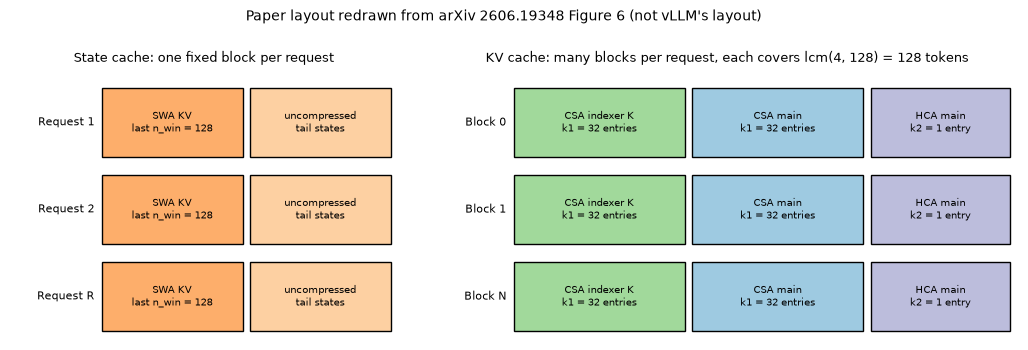

In [9]:
def box(axis, x, y, width, height, text, color):
    axis.add_patch(Rectangle((x, y), width, height, facecolor=color, edgecolor="black"))
    axis.text(x + width / 2, y + height / 2, text, ha="center", va="center", fontsize=7.5)


states = {(r["layer"], r["cache"]): r["states_in_block"] for r in contents.to_dict("records")}
figure, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.8), gridspec_kw={"width_ratios": [1, 1.5]})
for row, name in enumerate(("Request 1", "Request 2", "Request R")):
    y = 2 - row
    left.text(-0.05, y + 0.4, name, ha="right", va="center", fontsize=8)
    box(left, 0, y, 1.0, 0.8, "SWA KV\nlast n_win = 128", "#fdae6b")
    box(left, 1.05, y, 1.0, 0.8, "uncompressed\ntail states", "#fdd0a2")
left.set_xlim(-0.65, 2.1)
left.set_ylim(-0.1, 3.0)
left.axis("off")
left.set_title("State cache: one fixed block per request", fontsize=9)
for row, name in enumerate(("Block 0", "Block 1", "Block N")):
    y = 2 - row
    right.text(-0.05, y + 0.4, name, ha="right", va="center", fontsize=8)
    box(right, 0, y, 1.1, 0.8, f"CSA indexer K\nk1 = {states[('CSA layer', 'indexer')]} entries", "#a1d99b")
    box(right, 1.15, y, 1.1, 0.8, f"CSA main\nk1 = {states[('CSA layer', 'main')]} entries", "#9ecae1")
    box(right, 2.3, y, 0.9, 0.8, f"HCA main\nk2 = {states[('HCA layer', 'main')]} entry", "#bcbddc")
right.set_xlim(-0.5, 3.25)
right.set_ylim(-0.1, 3.0)
right.axis("off")
right.set_title(f"KV cache: many blocks per request, each covers lcm(4, 128) = {BLOCK_TOKENS} tokens", fontsize=9)
figure.suptitle("Paper layout redrawn from arXiv 2606.19348 Figure 6 (not vLLM's layout)", fontsize=10)
figure.subplots_adjust(top=0.82, left=0.03, right=0.99, wspace=0.08)
plt.close(figure)
figure

In [10]:
# 실패 재현: 압축률의 배수가 아닌 block_size
TOY_BUDGET = dict(gpu_total_bytes=96 * 2**30, weights_bytes=40 * 2**30, other_bytes=4 * 2**30)  # 수업이 정한 값
BAD_BLOCK_SIZE = 64

try:
    kv.capacity_estimate(V4, block_size=BAD_BLOCK_SIZE, **TOY_BUDGET)
except ValueError as error:
    print(type(error).__name__, "/", error)
print("vLLM의 식으로 보면 HCA 층의 block 안 상태 수:", BAD_BLOCK_SIZE, "//", 128, "=", BAD_BLOCK_SIZE // 128)

ValueError / block_size=64: DeepSeek-V4-Flash은 128의 배수여야 record가 나누어떨어집니다
vLLM의 식으로 보면 HCA 층의 block 안 상태 수: 64 // 128 = 0


**관찰할 것.** 메시지에서 요구하는 배수를 읽고, 그 수가 앞 표의 어느 값인지 찾으세요. 둘째 줄의 0이 왜 문제입니까? 이 `ValueError`는 수업 함수 `capacity_estimate`의 검사입니다. vLLM에 block 64를 넣어 실행해 본 적은 없으므로 어디서 어떻게 멈추는지는 말하지 않습니다. 코드에서 확인한 것은 `get_num_kernel_states`([`kv_cache_interface.py:231`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L231))의 나눗셈까지입니다.

**왜 이렇게 설계했나.** V4 보고서(arXiv 2606.19348) §3.5.1은 두 이유를 듭니다. SWA는 캐시 정책이 달라 PagedAttention의 "층마다 같은 정책" 가정을 깨므로 SWA와 꼬리를 상태 공간 모델의 상태처럼 따로 둔다는 것이고(P7-17), kernel은 정렬을 요구하므로 block이 덮는 token을 두 압축률의 최소공배수 배수로 맞춘다는 것입니다(P7-18). 5절 둘째 표의 256도 이 배수 조건을 만족합니다. V4.1 코드의 `block_stride_alignment`([`deepseek_v41/attention.py:1234`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L1234))도 `math.lcm`을 쓰지만 이 최소공배수와 다릅니다. kernel이 요구하는 바이트 정렬의 최소공배수이고 token 수의 최소공배수가 아닙니다(P7-18). vLLM의 구현은 이 그림과 같지 않습니다. 11절에서 봅니다(P7-63).

## 6. 층: KDA와 sparse 층, CSA2

세 번째 차원은 캐시를 가진 층 자체를 줄이는 것입니다. 방법이 두 가지입니다. 층을 통째로 다른 종류로 바꾸거나(GLM-5.3-Flash, Kimi), 층끼리 캐시를 나눠 씁니다(V4.1의 CSA2).

**먼저 예측하세요.** 아래 셀은 config 스냅샷으로 층 지도를 찍습니다. 실행 전에 적으세요. GLM-5.3-Flash는 `full_attn_layers`가 4층마다 하나입니다. 45층 중 token마다 KV가 쌓이는 층은 몇 개일까요? V4.1-Flash 40층 중 자기 main KV를 소유하는 층은 몇 개일까요? 짐작이어도 숫자로 적으세요.

In [11]:
SYMBOLS = {"kda": "k", "sparse_mla": "S", "swa_only": ".", "csa": "C", "hca": "H",
           "kv_source": "F", "index_source": "R", "consumer": "u"}
ROLE_ROWS = {model: kv.layer_table(model)["rows"] for model in (GLM, V4, V41)}

print(" " * 21, "".join(str(i // 10) if i % 10 == 0 else " " for i in range(45)))
for model, rows in ROLE_ROWS.items():
    print(f"{model:21s}", "".join(SYMBOLS[row["role"]] for row in rows))
print("k=kda  S=sparse_mla  .=swa_only  C=csa  H=hca  F=kv_source  R=index_source  u=consumer")
print("kv_source_layer_ids:", FIELDS[V41]["kv_source_layer_ids"], "/ index_source_layer_ids:", FIELDS[V41]["index_source_layer_ids"])

view.table([{"model": model, "role": role, "layers": sum(row["role"] == role for row in rows),
             "layers_with_main_record": sum(row["role"] == role and row["main_record_bytes"] > 0 for row in rows)}
            for model, rows in ROLE_ROWS.items() for role in dict.fromkeys(row["role"] for row in rows)])

                      0         1         2         3         4    
GLM-5.3-Flash         kkkSkkkSkkkSkkkSkkkSkkkSkkkSkkkSkkkSkkkSkkkSk
DeepSeek-V4-Flash     ..CHCHCHCHCHCHCHCHCHCHCHCHCHCHCHCHCHCHCHCHC
DeepSeek-V4.1-Flash   ..FuuuuuFuuuuuFuuuuuFuuuRuuuRuuuRuuuRuuu
k=kda  S=sparse_mla  .=swa_only  C=csa  H=hca  F=kv_source  R=index_source  u=consumer
kv_source_layer_ids: [2, 8, 14, 20] / index_source_layer_ids: [2, 8, 14, 20, 24, 28, 32, 36]


,model,role,layers,layers_with_main_record
0,GLM-5.3-Flash,kda,34,0
1,GLM-5.3-Flash,sparse_mla,11,11
2,DeepSeek-V4-Flash,swa_only,2,0
3,DeepSeek-V4-Flash,csa,21,21
4,DeepSeek-V4-Flash,hca,20,20
5,DeepSeek-V4.1-Flash,swa_only,2,0
6,DeepSeek-V4.1-Flash,kv_source,4,4
7,DeepSeek-V4.1-Flash,consumer,30,0
8,DeepSeek-V4.1-Flash,index_source,4,0


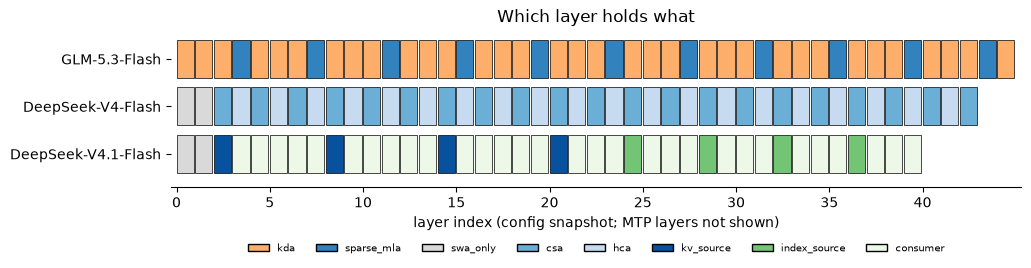

In [12]:
ROLE_COLORS = {"kda": "#fdae6b", "sparse_mla": "#3182bd", "swa_only": "#d9d9d9", "csa": "#6baed6", "hca": "#c6dbef",
               "kv_source": "#08519c", "index_source": "#74c476", "consumer": "#edf8e9"}
figure, axis = plt.subplots(figsize=(10.5, 2.9))
models = list(ROLE_ROWS)
for y, model in enumerate(models):
    for row in ROLE_ROWS[model]:
        axis.add_patch(Rectangle((row["layer"], -y), 0.92, 0.8, facecolor=ROLE_COLORS[row["role"]], edgecolor="black", linewidth=0.5))
axis.set_xlim(-0.3, 45.3)
axis.set_ylim(-len(models) + 0.7, 1.0)
axis.set_yticks([-y + 0.4 for y in range(len(models))], labels=models)
axis.set_xticks(range(0, 45, 5))
axis.set_xlabel("layer index (config snapshot; MTP layers not shown)")
axis.set_title("Which layer holds what")
axis.legend(handles=[Rectangle((0, 0), 1, 1, facecolor=color, edgecolor="black") for color in ROLE_COLORS.values()],
            labels=list(ROLE_COLORS), loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=len(ROLE_COLORS), fontsize=7.5, frameon=False)
for side in ("top", "right", "left"):
    axis.spines[side].set_visible(False)
figure.subplots_adjust(left=0.17, right=0.98, top=0.88, bottom=0.34)
plt.close(figure)
figure

**관찰할 것.** 표의 `layers_with_main_record` 칸을 모델별로 더해 예측과 비교하세요. V4.1의 `consumer` 행이 `layers`는 큰데 `layers_with_main_record`가 0인 것을 확인하세요. 지도의 두 번째 줄 `C`와 `H`가 교대로 나오는 것이 V4의 설정값 `compress_ratios`입니다(P7-14). `u`는 뒤의 표에서 Reuse로 읽는 층입니다.

### GLM-5.3-Flash: 층을 통째로 바꾼다

GLM-5.3-Flash는 `linear_attention` 층과 `deepseek_sparse_attention` 층을 섞습니다(P7-41). [Z.ai GLM-5.3-Flash 문서](https://docs.z.ai/guides/vlm/glm-5.3-flash)는 선형 attention이 상태 모델링으로 지역 의존성을 잡고 sparse attention이 가벼운 indexer로 전역 문맥을 가져온다고 설명합니다. 2026-11-02에 받은 이 문서 본문에서는 KDA라는 단어를 찾지 못했습니다. 다른 Z.ai 자료까지 본 것은 아니므로 Z.ai가 이 이름을 쓰는지는 단정하지 않습니다(P7-44). vLLM은 이 층을 `Glm5NextLinearAttention`([`glm5next/common/kda.py:163`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/kda.py#L163))로 `kda.py`에 두고 `_is_kda_layer`([`glm5next/common/model.py:130`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/model.py#L130))로 가르고, [vLLM 레시피](https://recipes.vllm.ai/zai-org/GLM-5.3-Flash)도 이 모델의 attention을 KDA라고 적습니다. 그래서 같은 계열로 읽습니다. 이 노트북의 `kda`는 코드가 쓰는 이름입니다.

KDA(Kimi Delta Attention)는 델타 규칙 재귀에 채널별 망각 게이트를 붙인 선형 attention입니다. token마다 늘어나는 KV 대신 head마다 고정 크기 재귀 상태 하나를 둡니다(arXiv 2510.26692 §3, §6.3, Kimi K3 보고서 §2.1.1, §5.1, P7-49). Kimi Linear 논문(arXiv 2510.26692 초록, §1)은 KDA 층과 MLA 층을 3:1로 섞어 긴 시퀀스 생성의 메모리와 KV cache 사용을 최대 75% 줄인다고 씁니다(48B 규모, 제작사 주장, P7-50).

상태 크기는 `kda_state_shape`([`mamba_utils.py:304`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/mamba/mamba_utils.py#L304))의 식에 config 값을 넣으면 나옵니다.

In [13]:
state = kv.glm_kda_fixed_state()
linear = FIELDS[GLM]["linear_attn_config"]
print("config linear_attn_config:", {key: linear[key] for key in ("num_heads", "head_dim", "short_conv_kernel_size")})
display(view.table([{name: state[name] for name in ("kind", "layers", "conv_bytes_per_state", "recurrent_bytes_per_state",
                                             "state_bytes_per_layer", "resident_states", "fixed_bytes_per_request")}]))
print("아래 P7-48은 미확인 항목입니다.")
with pd.option_context("display.max_colwidth", None):
    display(view.table([{"assumption": text} for text in state["assumptions"]]))

config linear_attn_config: {'num_heads': 64, 'head_dim': 128, 'short_conv_kernel_size': 4}


,kind,layers,conv_bytes_per_state,recurrent_bytes_per_state,state_bytes_per_layer,resident_states,fixed_bytes_per_request
0,estimate,34,147456,4194304,4341760,1,147619840


아래 P7-48은 미확인 항목입니다.


,assumption
0,"mamba_cache_mode none의 state 1벌이 하한이다. prefix caching을 켜면 align으로 바뀌어 더 많이 잡는다(P8-23, P8-24)."
1,"conv state는 BF16(model dtype), recurrent state는 float32다. 둘 다 dtype 설정이 auto일 때다. vllm/model_executor/layers/mamba/mamba_utils.py:139-141"
2,TP 샤딩과 page_size_padded는 계산하지 않았다. 실제 클래스 호출 값은 real_kda_table에 있다. vllm/v1/kv_cache_interface.py:1063-1070
3,"sparse MLA 층마다 tail ring(CircularBufferSpec)이 요청당 더 있지만 세지 않았다. vllm/models/glm5next/common/attention.py:156-177, :271"
4,측정이 아니라 코드 식에 config 값을 넣은 추정이다. GLM-5.3-Flash 전용 보고서는 찾지 못했다(P7-48).
5,KDA라는 이름은 config의 kda_layers와 vLLM의 kda.py에서 왔다. Z.ai 문서가 이 이름을 쓰는지는 확인하지 못했다(P7-44).


**관찰할 것.** `recurrent_bytes_per_state`를 `num_heads * head_dim * head_dim * 4`로 직접 계산해 맞춰 보세요. 4는 float32 바이트입니다(`recurrent_state_dtype`([`mamba_utils.py:141`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/mamba/mamba_utils.py#L141))). 식에 문맥 길이가 없는 것을 확인하세요. `conv_bytes_per_state`는 짧은 convolution의 상태입니다. `fixed_bytes_per_request`가 큰지 작은지는 비교 대상이 있어야 말할 수 있습니다. 9절에서 합니다. `kind`는 항상 `estimate`입니다. `assumption` 칸은 이 값의 조건과 넣지 않은 것을 적습니다. 하한이라는 줄, TP 샤딩 줄, tail ring 줄을 읽으세요. 마지막 줄은 이 층의 이름에 대한 단서입니다.

### V4.1-Flash: 층끼리 나눠 쓴다 (CSA2)

CSA2(arXiv 2609.19969 §2.3)는 V4의 CSA와 HCA 혼합을 버리고 하나로 합칩니다. 압축률 1도 특수한 경우로 포함하고, 압축의 겹침과 절대 위치 임베딩을 없앴으며, indexer K를 main KV에서 투영해 얻습니다(P7-22). 층마다 세 모드 중 하나로 고정됩니다(§2.3.1, 그림 4, P7-21).

| 모드 | main KV와 indexer K | indexer Q | top-k | 자기 층에서 계산 | 층 지도 |
|---|---|---|---|---|---|
| Full | 자기가 만듭니다 | 있음 | 새로 뽑습니다 | query, SWA KV | `F` |
| Reindex | 앞 Full 층 것을 재사용 | 있음 | 다시 점수를 매겨 새로 뽑습니다 | query, SWA KV | `R` |
| Reuse | 앞 Full 층 것을 재사용 | 없음 | 앞 층 것을 재사용 | query, SWA KV | `u` |

config에는 Full, Reindex, Reuse라는 말이 없습니다. `kv_source_layer_ids`와 `index_source_layer_ids`만 있습니다. 이것을 세 모드로 읽는 것은 arXiv 2609.19969 그림 3과 코드 주석에서 나온 추정입니다(P7-23). 코드는 V4.1 topology 주석([`deepseek_v41/attention.py:303`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L303))에서 압축 KV는 소유 층에만, indexer는 인덱스 소유 층에만 두고 소비 층은 가장 최근 소유 층을 쓴다고 적습니다. `get_kv_cache_spec`([`deepseek_v41/attention.py:1143`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L1143))은 소유 층이 아니면 `None`을 돌려주고, `index_k_cache`([`deepseek_v41/attention.py:434`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L434))도 소유 층에만 만듭니다(P7-61). `compress_ratios`는 2~19번 층이 2, 20~39번 층이 1입니다(P7-23).

**왜 이렇게 설계했나.** 보고서 §2.3.1은 main KV와 indexer K 공유가 저장을 줄이고 top-k 재사용이 indexer 연산을 줄이며, Reindex를 두면 cache를 공유하면서도 층마다 다른 항목을 고를 수 있다고 씁니다(P7-21). GLM 쪽 이유는 [Z.ai GLM-5.3-Flash 문서](https://docs.z.ai/guides/vlm/glm-5.3-flash)의 설명까지만 확인했습니다. 층을 바꾸는 쪽과 공유하는 쪽의 품질 차이는 이 수업이 측정하지 않았습니다.

## 7. CED와 Hierarchical Sparse Indexer

이 둘은 저장이 아니라 연산을 줄입니다. 2절의 식에는 나오지 않습니다.

### CED: prefill이 왜 절반이 되나

V4.1은 40층을 인코더 20층과 디코더 20층으로 나눕니다(arXiv 2609.19969 §2.1, 그림 3). 디코더 층의 global KV는 자기 은닉 상태가 아니라 인코더 마지막 층의 은닉 상태에서 층별 가중치로 투영합니다(§2.2 식 1, P7-20). prefill의 목적은 KV를 채우는 것이고, 디코더 global KV는 인코더만 돌아도 얻습니다. 남는 일은 SWA KV입니다. SWA KV는 층마다 자기 은닉 상태에서 만들기 때문에 디코더도 돌아야 하지만, 보고서는 마지막 창만 돌리는 근사를 택합니다(근사라는 점은 9절). 그래서 prefill 복잡도가 `O(NL)`에서 `O(NL/2 + n_win L/2)`가 됩니다. 활성 파라미터는 prefill 8B, decode 16B라고 적습니다(제작사 주장, P7-20).

아래는 이 식에 값을 넣어 본 것입니다. 단위는 token과 층의 곱이고 FLOPs가 아닙니다.

In [14]:
L = FIELDS[V41]["num_hidden_layers"]
N_WIN = FIELDS[V41]["sliding_window"]
view.table([{"new_tokens": n, "full_layer_tokens": n * L, "ced_layer_tokens": n * L // 2 + N_WIN * L // 2,
             "ced_over_full": round((n * L // 2 + N_WIN * L // 2) / (n * L), 3), "kind": "estimate"}
            for n in (128, 1_000, 16_000, 256_000, CONTEXT_1M)])

,new_tokens,full_layer_tokens,ced_layer_tokens,ced_over_full,kind
0,128,5120,5120,1.000,estimate
1,1000,40000,22560,0.564,estimate
2,16000,640000,322560,0.504,estimate
3,256000,10240000,5122560,0.500,estimate
4,1048576,41943040,20974080,0.500,estimate


**관찰할 것.** `ced_over_full` 칸이 `new_tokens`가 작을 때와 클 때 어떻게 다릅니까? 첫 행의 값이 왜 1.0인지 식으로 설명하세요. "prefill이 절반"은 새 입력이 창보다 충분히 길 때의 말입니다.

**코드.** vLLM에서 이 자르는 지점이 `cut`([`deepseek_v41/nvidia/model.py:805`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/nvidia/model.py#L805))입니다. config의 `kv_source_layer_ids` 마지막 값 20입니다. 이 경로의 로그 문구([`deepseek_v41/nvidia/model.py:831`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/nvidia/model.py#L831))가 동작을 적습니다. eager prefill step에서 그 층은 모든 token의 KV를 쓰고, 그 층의 나머지와 뒤 층들은 요청의 마지막 창만 돕니다. 항상 켜지는 것은 아닙니다. `swa_bounded_replay`([`config/cache.py:250`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L250))의 기본값은 참이지만 model runner V2가 필요하고, `swa_bounded_replay` 검사([`deepseek_v41/attention.py:530`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L530))는 prefill context parallelism과 ROCm에서도 끕니다. `_decoder_replay_supported`([`deepseek_v41/nvidia/model.py:1202`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/nvidia/model.py#L1202))는 pipeline, sequence parallel, microbatching 등에서 디코더 쪽을 끕니다.

### Hierarchical Sparse Indexer: 후보 풀

CSA2로 indexer 횟수가 줄어도 남은 indexer는 문맥 전체를 훑습니다. 디코더에서 첫 Full 층이 전체를 훑으면서 점수가 높은 위치 블록을 골라 후보 풀을 만들고, 이후 Reindex 층은 그 풀 안에서만 점수를 매깁니다. config 값은 `candidate_topk_blocks` 2048, `candidate_block_size` 8, `candidate_source_layer_id` 20입니다(arXiv 2609.19969 §2.3.2, 그림 5, P7-24). 풀 크기를 고정하면 뒤 indexer의 층당 점수 계산 수가 문맥 길이와 무관해진다는 것이 논문의 말입니다. 첫 Full 층의 전체 훑기는 남습니다.

아래는 질의 하나가 점수를 매기는 항목 수를 세어 본 것입니다. V4는 압축률 4인 21개 층이 각자 전체를 훑습니다. V4.1은 F 층 넷과 R 층 넷만 훑습니다. head 수는 V4가 64, V4.1이 32로 다른데(P7-31) 이 수에는 넣지 않았습니다.

In [15]:
POOL = FIELDS[V41]["candidate_topk_blocks"] * FIELDS[V41]["candidate_block_size"]


def scored_entries(context):
    full_encoder = 3 * context // 2                      # 2, 8, 14번 층, 압축률 2
    full_decoder = context                               # 20번 층, 압축률 1
    reindex_whole = 4 * context                          # 24, 28, 32, 36번 층이 전부 훑는 경우
    reindex_pool = 4 * min(POOL, context)                # 같은 층이 풀 안만 훑는 경우
    return {"context": context, "v4_scored": 21 * context // 4,
            "v41_scored_no_pool": full_encoder + full_decoder + reindex_whole,
            "v41_scored_with_pool": full_encoder + full_decoder + reindex_pool, "kind": "estimate"}


print("후보 풀 크기:", POOL)
view.table([scored_entries(context) for context in (16_000, 128_000, CONTEXT_1M)])

후보 풀 크기: 16384


,context,v4_scored,v41_scored_no_pool,v41_scored_with_pool,kind
0,16000,84000,104000,104000,estimate
1,128000,672000,832000,385536,estimate
2,1048576,5505024,6815744,2686976,estimate


**관찰할 것.** `context`가 커질 때 `v41_scored_no_pool`과 `v41_scored_with_pool`의 차이가 어떻게 달라집니까? `v41_scored_with_pool`이 그래도 문맥 길이를 따라 늘어나는 이유는 무엇입니까? 어느 층이 계속 전체를 훑는지 위 함수의 변수 이름에서 찾으세요. `v41_scored_no_pool`이 `v4_scored`보다 큰 이유도 압축률로 말해 보세요.

**코드와 논문의 차이 한 가지.** V4.1 indexer docstring([`deepseek_v41/attention.py:1265`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L1265))은 뒤 indexer가 점수를 후보 블록으로 마스킹한다고 적습니다. 실제로 후보만 계산하는 경로는 `indexer_sparse_logits`([`config/attention.py:94`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/attention.py#L94))이고 기본값이 거짓입니다. 그 설정의 주석은 mxfp4 indexer와 SM100급 GPU 등을 요구하고, 대략 32K token 이상의 긴 문맥에서 이득이고 그보다 짧으면 느리다고 적습니다. 따라서 위 `v41_scored_with_pool`은 논문의 설명과 이 경로의 값이고, 기본 설정의 연산량으로 읽지 않습니다. 이 주석의 32K를 우리가 측정한 적은 없습니다.

제작사는 이런 개선을 모아 문맥이 4K에서 1M으로 256배 늘 때 V4.1의 decode FLOPs가 1/4만 는다고 씁니다(제작사 주장, P7-30, 그림 2의 곡선 값은 읽지 않았습니다).

**왜 이렇게 설계했나.** 보고서 §2.1은 입력이 많은 에이전트 작업에서 새 입력과 캐시되지 않은 입력을 처리하는 비용을 낮추려는 것이 CED의 목적이라고 씁니다(제작사 주장). §2.3.2는 극단적으로 긴 문맥에서 남은 indexer의 전체 훑기가 큰 병목으로 남기 때문에 후보 풀을 도입했다고 씁니다.

## 8. 890과 3514.25를 코드로 다시 세기

이제 2절의 식을 진짜로 돌립니다. 제작사 값은 1절에서 봤습니다. 이 절의 질문은 그 값이 어떤 항으로 이루어졌고, 우리가 가진 config와 코드 값으로 맞출 수 있는가입니다.

입력은 다음이 전부입니다.

| 모델 | 소유 층의 압축률(설정값) | main record | indexer record |
|---|---|---|---|
| V4.1-Flash | `kv_source_layer_ids`의 네 층: 2, 2, 2, 1 | 288B | 68B |
| V4-Flash | CSA 21층: 4, HCA 20층: 128 (indexer는 CSA 층에만) | 584B | 68B |

**먼저 예측하세요.** 실행 전에 손으로 계산해 적으세요. V4.1에서 main 몫과 indexer 몫은 각각 몇 바이트입니까? V4에서 CSA main, HCA main, indexer 세 항은 각각 몇 바이트입니까?

In [16]:
def parts_table(model):
    result = kv.global_kv_per_token(model)
    return view.table([{"model": model, "cache": part["cache"], "layers": len(part["layers"]),
                        "tokens_per_state": part["tokens_per_state"], "record_bytes": part["record_bytes"],
                        "bytes_per_token": part["bytes_per_token"]} for part in result["parts"]])


display(parts_table(V41))
display(parts_table(V4))

results = {model: kv.global_kv_per_token(model) for model in (V41, V4)}
view.table([{"model": model, "main_bytes_per_token": r["main_bytes_per_token"], "indexer_bytes_per_token": r["indexer_bytes_per_token"],
             "total_bytes_per_token": r["total_bytes_per_token"], "reported_bytes_per_token": r["reported_bytes_per_token"], "kind": r["kind"]}
            for model, r in results.items()])

,model,cache,layers,tokens_per_state,record_bytes,bytes_per_token
0,DeepSeek-V4.1-Flash,main,3,2,288,432.0
1,DeepSeek-V4.1-Flash,indexer,3,2,68,102.0
2,DeepSeek-V4.1-Flash,main,1,1,288,288.0
3,DeepSeek-V4.1-Flash,indexer,1,1,68,68.0


,model,cache,layers,tokens_per_state,record_bytes,bytes_per_token
0,DeepSeek-V4-Flash,main,21,4,584,3066.00
1,DeepSeek-V4-Flash,indexer,21,4,68,357.00
2,DeepSeek-V4-Flash,main,20,128,584,91.25


,model,main_bytes_per_token,indexer_bytes_per_token,total_bytes_per_token,reported_bytes_per_token,kind
0,DeepSeek-V4.1-Flash,720.00,170.0,890.00,890,reproduced
1,DeepSeek-V4-Flash,3157.25,357.0,3514.25,3514,reproduced


In [17]:
# 함수에 기대지 않고 식 그대로 다시 쓴다. 위 표와 같아야 한다.
v41_by_hand = 288 * (3 / 2 + 1 / 1) + 68 * (3 / 2 + 1 / 1)
v4_by_hand = 584 * 21 / 4 + 584 * 20 / 128 + 68 * 21 / 4
print("V4.1 손 계산:", v41_by_hand, "/ 함수:", results[V41]["total_bytes_per_token"])
print("V4 손 계산:", v4_by_hand, "/ 함수:", results[V4]["total_bytes_per_token"])

V4.1 손 계산: 890.0 / 함수: 890.0
V4 손 계산: 3514.25 / 함수: 3514.25


**관찰할 것.** 표의 `bytes_per_token` 칸을 예측과 비교하세요. 마지막 표의 `total_bytes_per_token`과 `reported_bytes_per_token`을 나란히 읽고 `kind` 칸을 읽으세요. V4의 소수 .25가 그림의 3,514가 되려면 어떻게 되어야 합니까?

`kind`가 `reproduced`인 것은 산수가 맞았다는 뜻입니다. 여기까지만 말할 수 있습니다.

- 보고서에 이 식이 적혀 있지는 않습니다. 우리가 구조에서 세어 본 식이 그림의 값과 맞았습니다.
- `kv_source`를 Full로 읽는 것은 추정입니다(P7-23).
- global KV만 셉니다. SWA와 꼬리는 들어가지 않습니다. 그래서 persistent KV의 1/8 같은 값은 이 계산으로 나오지 않습니다(9절, P7-27).
- 제일 중요한 것은 저장 형식입니다. 아래에서 봅니다.

In [18]:
with pd.option_context("display.max_colwidth", None):
    display(view.table([{"model": model, "assumption": text} for model in (V41, V4)
                        for text in kv.global_kv_per_token(model)["assumptions"]]))

,model,assumption
0,DeepSeek-V4.1-Flash,main record 288B는 nvfp4_ds_mla(SM100 전용)일 때다. fp8_ds_mla면 528B 또는 584B다. vllm/models/deepseek_v41/attention.py:513-527
1,DeepSeek-V4.1-Flash,"indexer record 68B는 indexer_kv_dtype=mxfp4일 때다. SM10x에서만 받는다(V4.1은 코드 읽기, 같은 함수를 V4에서 실행). auto는 fp8로 풀려 132B다. vllm/v1/attention/backends/mla/indexer.py:61, :91, vllm/models/deepseek_v41/attention.py:92-100"
2,DeepSeek-V4.1-Flash,"SWA 캐시와 압축 꼬리 상태는 세지 않았다. global KV만 센다(P7-27, P7-29)."
3,DeepSeek-V4.1-Flash,"kv_source와 index_source를 논문의 Full, Reindex 층으로 읽는 것은 추정이다(P7-23)."
4,DeepSeek-V4-Flash,main record 584B는 --kv-cache-dtype fp8_ds_mla일 때다. vllm/models/deepseek_v4/attention.py:878
5,DeepSeek-V4-Flash,"indexer record 68B는 indexer_kv_dtype=mxfp4일 때다. SM10x에서만 받고 SM90은 거부한다(실제 클래스 실행). auto는 fp8로 풀려 132B다. vllm/v1/attention/backends/mla/indexer.py:61, :91, vllm/models/deepseek_v4/attention.py:1005-1014"
6,DeepSeek-V4-Flash,"SWA 캐시와 압축 꼬리 상태는 세지 않았다. global KV만 센다(P7-17, P7-29)."


**관찰할 것.** `assumption` 칸에서 288B와 68B가 각각 어떤 조건의 값인지 읽으세요. 코드로 확인합니다. `dsa_indexer_uses_fp4`([`indexer.py:59`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/indexer.py#L59))는 `auto`를 fp8로 풀고, 그 값이 132B입니다. mxfp4는 `DSA_INDEXER_KV_DTYPES`([`indexer.py:56`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/indexer.py#L56)) 위 주석이 opt-in이라고 적습니다. 켠다고 다 받지도 않습니다. CUDA에서는 SM10x(B200, GB200 같은 Blackwell datacenter GPU)만 받고, 그 밖의 GPU는 SM120까지 포함해 `is_device_capability_family` 검사([`indexer.py:90`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/indexer.py#L90))에서 `ValueError`로 거부됩니다. V4를 SM90에서 거부하는 것은 실제 클래스 실행에서 봤습니다(`data/reference_specs.json`의 `rejected_by_code`). V4.1은 그 조합을 실행하지 않았고 같은 함수를 지나는 것을 코드로만 읽었습니다. ROCm은 같은 함수의 다른 분기이고 V4.1, CDNA4, aiter를 따로 요구합니다. 그래서 68B를 쓰는 890과 3,514.25는 SM10x 조건의 값입니다. main 쪽은 `_resolve_dsv4_kv_cache_dtype`([`deepseek_v41/attention.py:132`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L132))이 `auto`를 그 kernel이 선호하는 record로 풀고, `packed_kv_cache_dtype`([`deepseek_v41/nvidia/flash_mla_mega_attn.py:202`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/nvidia/flash_mla_mega_attn.py#L202))은 NVFP4를 읽는 유일한 kernel이라 거기서 `nvfp4_ds_mla`로 풉니다. `nvfp4_ds_mla` 검사([`deepseek_v41/attention.py:523`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L523))는 SM100이 아니면 이 형식을 거부합니다.

그래서 890은 "V4.1을 띄우면 나오는 값"이 아닙니다. 층별 가중치는 그대로 두고 record만 바꿔 봅니다. 라이브러리에 없는 손 계산이고, 결과는 추정입니다. packed 배치만 다룹니다. plain row를 쓰는 backend는 또 다른 값이 됩니다(`_resolve_dsv4_kv_cache_dtype`([`deepseek_v41/attention.py:132`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L132))). 어느 형식이 잡혔는지는 서버 시작 로그의 KV cache 형식 로그([`deepseek_v41/attention.py:161`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L161))에서 읽는 자리이고, 이 수업에서는 서버를 돌려 확인하지 않았습니다.

In [19]:
def reweigh(model, main_record, indexer_record):
    """parts에서 층별 1/tokens_per_state 합만 가져와 record를 바꿔 끼운다."""
    parts = kv.global_kv_per_token(model)["parts"]
    weight = lambda cache: sum(len(p["layers"]) / p["tokens_per_state"] for p in parts if p["cache"] == cache)
    return main_record * weight("main") + indexer_record * weight("indexer")


FORMATS = [(V41, "nvfp4_ds_mla", 288, "mxfp4", 68, "SM100, indexer_kv_dtype=mxfp4 opt-in"),
           (V41, "nvfp4_ds_mla", 288, "fp8", 132, "FlashMLA mega kernel path, indexer auto"),
           (V41, "fp8_ds_mla V4.1 record", 528, "fp8", 132, "SM100, other packed path"),
           (V41, "fp8_ds_mla V4 record", 584, "fp8", 132, "packed path off SM100"),
           (V4, "fp8_ds_mla", 584, "mxfp4", 68, "SM10x, indexer_kv_dtype=mxfp4 opt-in"),
           (V4, "fp8_ds_mla", 584, "fp8", 132, "indexer auto")]
sensitivity = []
for model, main_format, main_record, indexer_format, indexer_record, when in FORMATS:
    total = reweigh(model, main_record, indexer_record)
    matched = round(total) == kv.global_kv_per_token(model)["reported_bytes_per_token"]
    sensitivity.append({"model": model, "main_format": main_format, "indexer_format": indexer_format, "bytes_per_token": total,
                        "kind": "reproduced" if matched else "estimate", "when": when})
with pd.option_context("display.max_colwidth", None):
    display(view.table(sensitivity))

,model,main_format,indexer_format,bytes_per_token,kind,when
0,DeepSeek-V4.1-Flash,nvfp4_ds_mla,mxfp4,890.00,reproduced,"SM100, indexer_kv_dtype=mxfp4 opt-in"
1,DeepSeek-V4.1-Flash,nvfp4_ds_mla,fp8,1050.00,estimate,"FlashMLA mega kernel path, indexer auto"
2,DeepSeek-V4.1-Flash,fp8_ds_mla V4.1 record,fp8,1650.00,estimate,"SM100, other packed path"
3,DeepSeek-V4.1-Flash,fp8_ds_mla V4 record,fp8,1790.00,estimate,packed path off SM100
4,DeepSeek-V4-Flash,fp8_ds_mla,mxfp4,3514.25,reproduced,"SM10x, indexer_kv_dtype=mxfp4 opt-in"
5,DeepSeek-V4-Flash,fp8_ds_mla,fp8,3850.25,estimate,indexer auto


**관찰할 것.** `kind`가 `reproduced`인 행은 어느 두 행입니까? 나머지 행의 `when` 칸을 읽고 `bytes_per_token`이 어떻게 달라지는지 보세요. V4.1 행들에서 가장 큰 값과 가장 작은 값의 비를 계산해, 1절 표의 `shrink_from_previous` 마지막 값과 나란히 놓아 보세요.

### GLM-5.3-Flash는 추정으로만

GLM-5.3-Flash에는 맞춰 볼 제작사 값이 없습니다. 그림 1(b)는 DeepSeek 모델만 적고, Z.ai가 낸 것은 GLM-5.3 대비 attention 연산 3.01배, KV cache 4.44배라는 비율입니다(제작사 주장, P7-46). 측정한 문맥 길이와 하드웨어는 문서에 없습니다. 이 4.44배를 config로 재현하지 못했습니다(P7-47, 미확인). 이 모델의 전용 보고서도 찾지 못했습니다(P7-48, 미확인). 그래서 같은 식을 돌리되 `kind`는 `estimate`입니다.

In [20]:
glm = kv.global_kv_per_token(GLM)
display(parts_table(GLM))
display(view.table([{"model": GLM, "total_bytes_per_token": glm["total_bytes_per_token"],
                     "reported_bytes_per_token": glm["reported_bytes_per_token"] or "-", "kind": glm["kind"]},
                    {"model": GLM + " if main is fp8_ds_mla 656B", "total_bytes_per_token": 656 * 11 + glm["indexer_bytes_per_token"],
                     "reported_bytes_per_token": "-", "kind": "estimate"}]))
print("아래 P7-47은 미확인 항목입니다.")
with pd.option_context("display.max_colwidth", None):
    display(view.table([{"assumption": text} for text in glm["assumptions"]]))

,model,cache,layers,tokens_per_state,record_bytes,bytes_per_token
0,GLM-5.3-Flash,main,11,1,1024,11264.0
1,GLM-5.3-Flash,indexer,11,4,132,363.0


,model,total_bytes_per_token,reported_bytes_per_token,kind
0,GLM-5.3-Flash,11627.0,-,estimate
1,GLM-5.3-Flash if main is fp8_ds_mla 656B,7579.0,-,estimate


아래 P7-47은 미확인 항목입니다.


,assumption
0,"제작사가 낸 토큰당 바이트 값이 없어 맞춰 볼 수 없다. Z.ai가 자체 보고한 4.44배는 이 값으로 재현되지 않는다(P7-46, P7-47)."
1,main은 BF16 512원소(rope 0)로 놓았다. Z.ai 비교가 BF16 기준이어서다. 실제 cache dtype은 서버 설정을 따른다(P7-46).
2,indexer record 132B는 FP8 값 128B와 FP32 scale 4B다. vllm/models/glm5next/common/attention.py:261
3,"KDA 고정 state, tail ring, hybrid pool padding은 토큰당 값에 들어가지 않는다(P2-61, P2-62)."


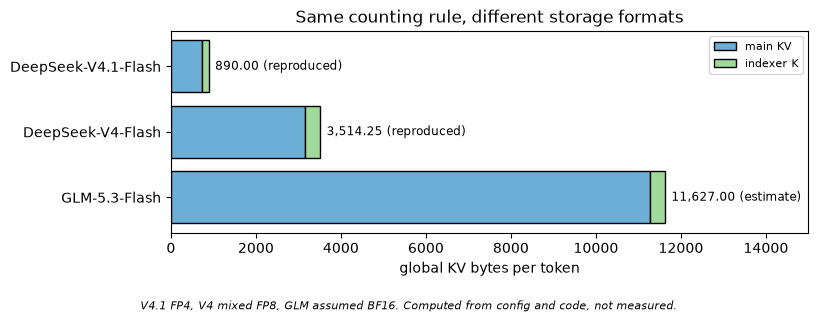

In [21]:
stack = {model: kv.global_kv_per_token(model) for model in (V41, V4, GLM)}
figure, axis = plt.subplots(figsize=(8.5, 3.2))
names = list(stack)
mains = [stack[m]["main_bytes_per_token"] for m in names]
indexers = [stack[m]["indexer_bytes_per_token"] for m in names]
axis.barh(names, mains, color="#6baed6", edgecolor="black", label="main KV")
axis.barh(names, indexers, left=mains, color="#a1d99b", edgecolor="black", label="indexer K")
axis.invert_yaxis()
axis.set_xlim(0, 15_000)
for y, m in enumerate(names):
    axis.text(stack[m]["total_bytes_per_token"] + 150, y, f"{stack[m]['total_bytes_per_token']:,.2f} ({stack[m]['kind']})", va="center", fontsize=8.5)
axis.set_xlabel("global KV bytes per token")
axis.set_title("Same counting rule, different storage formats")
axis.legend(loc="upper right", fontsize=8)
figure.text(0.5, 0.01, "V4.1 FP4, V4 mixed FP8, GLM assumed BF16. Computed from config and code, not measured.", ha="center", fontsize=8, style="italic")
figure.subplots_adjust(left=0.22, right=0.97, bottom=0.25)
plt.close(figure)
figure

**관찰할 것.** 표에서 `reported_bytes_per_token` 칸이 `-`인 것과 `kind` 칸을 확인하세요. 둘째 행은 `fp8_ds_mla`일 때의 `state_content_bytes`([`mla_attention.py:1365`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/mla_attention.py#L1365)) 값으로 바꿔 끼운 손 계산입니다. FLASHMLA_SPARSE 주석([`flashmla_sparse.py:220`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/flashmla_sparse.py#L220))이 이 조합을 언급합니다. 그림의 세 막대는 저장 형식이 다릅니다. 막대 길이 차이를 모두 구조의 차이로 읽으면 틀립니다. 그 분해는 10절에서 합니다.

### 세 값을 나란히: 제작사 값, record 합, 실제 stride

지금까지 맞춘 것은 record를 더한 값입니다. 메모리는 record 단위로 잡히지 않습니다. vLLM은 층마다 page를 잡아 한 group의 page를 이어 붙이고, page와 block 간격을 kernel이 요구하는 정렬에 맞춰 올립니다. block 하나가 실제로 차지하는 byte가 stride이고, stride를 block 크기로 나눈 값이 pool에서 실제로 쓰는 토큰당 byte입니다. 이 값을 정하는 함수가 `_get_kv_cache_bytes_per_block`([`kv_cache_utils.py:1520`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1520))입니다.

이 값은 계산이 아니라 실제 클래스 실행 기록입니다. 실제 층 클래스와 `get_kv_cache_groups`, `get_kv_cache_configs`를 CPU에서 불러 `data/reference_specs.json`에 저장해 두었고, `real_stride`와 `real_pages`가 그것을 읽습니다. 저장 형식은 각 모델의 record 합이 가정한 것과 같습니다.

**먼저 예측하세요.** 입력은 5절 둘째 표의 `bytes_in_block`입니다. V4의 `fp8_ds_mla` 형식은 page를 576B의 배수로 올립니다(`alignment`([`deepseek_v4/attention.py:873`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L873))). 실행 전에 적으세요. (1) CSA main, CSA indexer, HCA main의 값을 576의 배수로 올리면 각각 얼마입니까? (2) 셋 중 비율로 가장 크게 늘어나는 것은 무엇입니까? (3) 세 모델 중 실제 값이 record 합보다 비율로 가장 크게 커지는 모델은 무엇일까요?

In [22]:
three_way = []
for model in (V41, V4, GLM):
    counted = kv.global_kv_per_token(model)
    stride = kv.real_stride(model)
    reported = counted["reported_bytes_per_token"]
    gap = stride["bytes_per_token"] - stride["record_bytes_per_token"]
    three_way.append({"model": model, "reported_bytes_per_token": reported or "none",
                      "record_sum_bytes_per_token": counted["total_bytes_per_token"], "record_sum_kind": counted["kind"],
                      "real_stride_bytes_per_token": round(stride["bytes_per_token"], 2), "real_stride_kind": stride["kind"],
                      "padding_bytes_per_token": round(gap, 2), "padding_percent": round(100 * gap / stride["record_bytes_per_token"], 2),
                      "block_size": stride["block_size"], "block_stride_bytes": int(stride["block_stride_bytes"])})
display(view.table(three_way))
with pd.option_context("display.max_colwidth", None):
    display(view.table([{"real_class_limit": text} for text in kv.REAL_CLASS_ASSUMPTIONS]))

,model,reported_bytes_per_token,record_sum_bytes_per_token,record_sum_kind,real_stride_bytes_per_token,real_stride_kind,padding_bytes_per_token,padding_percent,block_size,block_stride_bytes
0,DeepSeek-V4.1-Flash,890,890.00,reproduced,896.00,real_class,6.00,0.67,128,114688
1,DeepSeek-V4-Flash,3514,3514.25,reproduced,3584.25,real_class,70.00,1.99,256,917568
2,GLM-5.3-Flash,none,11627.00,estimate,11631.53,real_class,4.53,0.04,4352,50620416


,real_class_limit
0,"CPU에서 실제 층 클래스와 get_kv_cache_groups, get_kv_cache_configs를 부른 값이다. 서버를 띄우지 않았고 메모리를 재지 않았다."
1,"SM 값, backend, weight 커널, FlashInfer 유무를 패치했다. 어느 GPU에서 어느 backend가 잡히는지는 이 값으로 말할 수 없다."
2,TP4는 TP 그룹만 값으로 바꾼 호출이다. 실제 4-GPU 실행이 아니다.
3,모델 클래스 전체는 만들지 못해 층만 만들었다. spec 5의 group 수에 MTP drafter 층은 들어 있지 않다.


,model,cache,layers,tokens_per_state,unpadded_page_bytes,page_bytes,page_growth_percent,record_bytes_per_token,page_bytes_per_token,added_bytes_per_token,kind
0,DeepSeek-V4.1-Flash,main,3,2,18432,18432,0.0,432.00,432.00,0.00,real_class
1,DeepSeek-V4.1-Flash,main,1,1,36864,36864,0.0,288.00,288.00,0.00,real_class
2,DeepSeek-V4.1-Flash,indexer,3,2,4352,4608,5.9,102.00,108.00,6.00,real_class
3,DeepSeek-V4.1-Flash,indexer,1,1,8704,8704,0.0,68.00,68.00,0.00,real_class
4,DeepSeek-V4-Flash,main,21,4,37376,37440,0.2,3066.00,3071.25,5.25,real_class
5,DeepSeek-V4-Flash,main,20,128,1168,1728,47.9,91.25,135.00,43.75,real_class
6,DeepSeek-V4-Flash,indexer,21,4,4352,4608,5.9,357.00,378.00,21.00,real_class
7,GLM-5.3-Flash,main,11,1,4456448,4456448,0.0,11264.00,11264.00,0.00,real_class
8,GLM-5.3-Flash,indexer,11,4,143616,143616,0.0,363.00,363.00,0.00,real_class


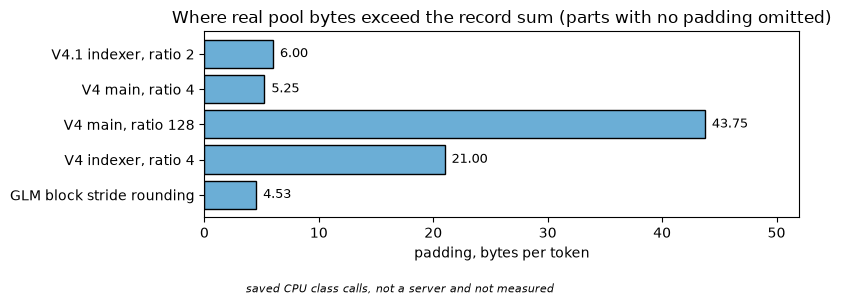

In [23]:
page_rows, padding_bars = [], []
for model, short in ((V41, "V4.1"), (V4, "V4"), (GLM, "GLM")):
    block = kv.real_block_size(model)
    added_total = 0.0
    for page in kv.real_pages(model):
        unpadded = block // page["tokens_per_state"] * page["record_bytes"]
        added = page["page_bytes_per_token"] - page["record_bytes_per_token"]
        added_total += added
        page_rows.append({"model": model, "cache": page["cache"], "layers": page["layers"], "tokens_per_state": page["tokens_per_state"],
                          "unpadded_page_bytes": unpadded, "page_bytes": page["page_bytes"],
                          "page_growth_percent": round(100 * (page["page_bytes"] / unpadded - 1), 1),
                          "record_bytes_per_token": page["record_bytes_per_token"], "page_bytes_per_token": page["page_bytes_per_token"],
                          "added_bytes_per_token": added, "kind": page["kind"]})
        if added:
            padding_bars.append((f"{short} {page['cache']}, ratio {page['tokens_per_state']}", added))
    stride = kv.real_stride(model)
    leftover = stride["bytes_per_token"] - stride["record_bytes_per_token"] - added_total
    if leftover > 0:
        padding_bars.append((f"{short} block stride rounding", leftover))
display(view.table(page_rows))

figure, axis = plt.subplots(figsize=(8.5, 3.0))
labels, values = zip(*padding_bars)
axis.barh(labels, values, color="#6baed6", edgecolor="black")
axis.invert_yaxis()
axis.set_xlim(0, 52)
for y, value in enumerate(values):
    axis.text(value + 0.6, y, f"{value:.2f}", va="center", fontsize=9)
axis.set_xlabel("padding, bytes per token")
axis.set_title("Where real pool bytes exceed the record sum (parts with no padding omitted)")
figure.text(0.5, 0.01, "saved CPU class calls, not a server and not measured", ha="center", fontsize=8, style="italic")
figure.subplots_adjust(left=0.27, right=0.97, top=0.88, bottom=0.26)
plt.close(figure)
figure

**관찰할 것.** 첫 표에서 `record_sum_bytes_per_token`과 `real_stride_bytes_per_token`을 나란히 읽고 `padding_percent` 칸을 예측과 비교하세요. 페이지 표에서는 `unpadded_page_bytes`와 `page_bytes`가 다른 행을 찾으세요. 그림에서 가장 긴 막대는 어느 항입니까?

세 값은 서로 다른 것을 말합니다.

| 값 | 코드의 `kind` | 말하는 것 |
|---|---|---|
| 제작사 값 | `reported` | 보고서 그림에 적힌 값입니다. GLM-5.3-Flash에는 없습니다 |
| record 합 | `reproduced`, GLM은 `estimate` | 층별 record 크기를 곱하고 더한 값입니다. 제작사 값과 맞았다는 것은 이 산수까지입니다 |
| 실제 stride | `real_class` | 실제 클래스가 pool의 block 하나에 잡는 byte를 block 크기로 나눈 값입니다. padding이 들어 있습니다 |

제작사 그림이 padding을 뺀 값이라고 보고서가 적은 것은 아닙니다. 우리가 아는 것은 record 합이 그림과 맞고, 실제 클래스 값이 그보다 크다는 것입니다.

padding이 생기는 자리는 모델마다 다릅니다.

- **V4.** main과 indexer의 모든 page를 576B 배수로 올립니다(`alignment`([`deepseek_v4/attention.py:873`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L873)), `alignment`([`deepseek_v4/attention.py:919`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L919))). CSA main은 37,376에서 37,440으로, indexer는 4,352에서 4,608로, HCA main은 1,168에서 1,728로 갑니다. HCA는 block 256에 record 2개뿐이라 올림이 48%나 됩니다. 세 항의 차이 5.25 + 21 + 43.75가 70이고 3,514.25와 3,584.25의 차이입니다.
- **V4.1.** 한 block 안의 모든 page에 512B 정렬 하나를 씁니다(`self.kv_page_alignment`([`deepseek_v41/attention.py:522`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L522)), `page_alignment`([`deepseek_v41/attention.py:1216`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L1216))). main page와 압축률 1인 indexer page는 이미 512의 배수입니다. 압축률 2인 indexer 3층만 4,352에서 4,608로 올라갑니다. 3 × 256B / 128 token이 6B이고 890과 896의 차이입니다.
- **GLM-5.3-Flash.** main과 indexer page에는 padding이 없습니다. 대신 page 합을 정렬값들의 최소공배수의 배수로 올립니다(`round_up`([`kv_cache_utils.py:1551`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1551))). main 쪽 1,024B는 record 1행입니다(`align_blocks_to_rows`([`sparse_utils.py:44`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/sparse_utils.py#L44))). indexer 쪽 8,448B는 kernel block 하나의 page, 64 state × 132B입니다(`customize_attention_spec`([`utils.py:476`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/worker/utils.py#L476)), `Glm5NextIndexerBackend`([`indexer.py:296`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/indexer.py#L296))). 최소공배수는 33,792이고, page 합 50,600,704가 stride 50,620,416이 됩니다. block 4352로 나누면 11,631.53입니다.

**왜 이렇게 설계했나.** V4 `get_kv_cache_spec`의 주석([`deepseek_v4/attention.py:861`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L861))은 이 형식이 576B 정렬을 요구한다고 적고, V4.1 주석([`deepseek_v41/attention.py:1145`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L1145))은 page를 decode kernel의 읽기 간격(TMA stride)에 맞춰 올린다고 적습니다. indexer까지 같은 padding을 갖는 이유는 main과 한 물리 block을 쓰고 stride가 그 안 모든 page의 합이기 때문입니다(주석 [`deepseek_v41/attention.py:1227`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L1227)). kernel 쪽 이유를 더 파고들지는 않았습니다.

**이 값의 한계.** 첫 표 아래 `real_class_limit` 칸의 네 줄이 조건입니다. 특히 GLM-5.3-Flash의 값은 서버 값이 아니라 클래스 호출 값입니다. 모델 클래스 전체는 `tilelang`이 없어 만들지 못했고 attention 층 45개만 만들었으며, backend는 시나리오로 정했고 SM 값, weight 커널, FlashInfer 유무는 대역으로 세웠습니다(패치 10개, `data/reference_specs.json`의 `patches`). 시작 로그나 실제 점유가 이 값과 같다고 말하지 않습니다. record 합 11,627도 그대로 `estimate`입니다.

In [24]:
KEEP = ["model", "scenario", "cache_dtype", "main_record_bytes", "indexer_record_bytes", "block_size", "group_count", "group_layers", "stride_bytes_per_token"]
formats = view.table(kv.real_scenarios(), KEEP)
formats["stride_bytes_per_token"] = formats["stride_bytes_per_token"].round(2)
formats = formats.drop_duplicates(subset=[name for name in KEEP if name not in ("scenario", "group_layers")]).reset_index(drop=True)
with pd.option_context("display.max_colwidth", None):
    display(formats)

,model,scenario,cache_dtype,main_record_bytes,indexer_record_bytes,block_size,group_count,group_layers,stride_bytes_per_token
0,GLM-5.3-Flash,glm.flashmla.bf16,auto,1024,132,4352,6,"[9, 9, 8, 8, 22, 11]",11631.53
1,GLM-5.3-Flash,glm.flashmla.bf16.spec5,auto,1024,132,4480,6,"[9, 9, 8, 8, 22, 11]",11631.09
2,GLM-5.3-Flash,glm.flashmla.fp8_ds_mla,fp8_ds_mla,656,132,8576,5,"[12, 11, 11, 22, 11]",7592.96
3,GLM-5.3-Flash,glm.flashmla.nvfp4_ds_mla,nvfp4_ds_mla,352,132,8576,7,"[7, 7, 7, 7, 6, 22, 11]",4235.33
4,GLM-5.3-Flash,glm.flashinfer_sm90.fp8,fp8,512,132,8576,6,"[9, 9, 8, 8, 22, 11]",5995.16
5,GLM-5.3-Flash,glm.flashinfer_sm100.fp8,fp8,512,132,8576,6,"[9, 9, 8, 8, 22, 11]",6052.30
6,GLM-5.3-Flash,glm.flashinfer_sm120.auto,fp8_ds_mla,656,132,8704,5,"[12, 11, 11, 22, 11]",7640.47
7,GLM-5.3-Flash,glm.flashmla.bf16.tp4,auto,1024,132,1152,6,"[9, 9, 8, 8, 22, 11]",11645.33
8,DeepSeek-V4-Flash,v4.flashmla.auto,fp8_ds_mla,584,132,256,5,"[22, 21, 62, 42, 20]",3915.00
9,DeepSeek-V4-Flash,v4.flashmla_sm100.mxfp4,fp8_ds_mla,584,68,256,5,"[22, 21, 62, 42, 20]",3584.25


**관찰할 것.** `model` 칸이 같은 행끼리 `cache_dtype`과 `group_count` 칸을 비교하세요. `stride_bytes_per_token` 칸에서 GLM의 `fp8_ds_mla` 행을 찾아, 앞 표의 손 계산 7,579와 비교하세요. `cache_dtype`의 `auto`는 설정값을 그대로 둔 것이고 이때 record가 1024B이면 BF16입니다. 시나리오 29개 중 이 칸들의 값이 같은 것은 한 행만 남겼습니다.

표에서 두 가지를 읽습니다.

- **block 크기.** GLM-5.3-Flash의 BF16은 4352이고, TP4에서 1152, `num_spec` 5에서 4480입니다. `fp8`, `fp8_ds_mla`, `nvfp4_ds_mla`는 8576이고 SM120 FlashInfer는 8704입니다. V4는 256, V4.1은 SM90 64, SM100 128입니다. 어느 GPU에서 어느 backend가 잡히는지는 이 표로 말할 수 없습니다.
- **group 수.** 저장 형식에 따라 움직여서 모델당 단일 값이 없습니다. GLM-5.3-Flash는 BF16과 `fp8` 6, `fp8_ds_mla` 5, `nvfp4_ds_mla` 7입니다. V4는 이 표에서 모두 5, V4.1은 6, 7, 9입니다. `_get_packed_kv_cache_groups`([`kv_cache_utils.py:1860`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/core/kv_cache_utils.py#L1860))의 docstring은 padding이 가장 적은 반복 수를 고른다고 적습니다. 형식별 수가 왜 그 값인지 이 실행에서 분해해 확인하지는 않았습니다. main과 indexer는 모든 시나리오에서 한 group에 들어갔습니다. MTP drafter 층은 만들지 않았으므로 `num_spec` 5의 group 수에 들어 있지 않습니다.

## 9. 아무도 피하지 못하는 비용

### 고정 state는 저절로 작지 않다

"문맥 길이에 무관하다"는 "작다"가 아닙니다. GLM-5.3-Flash의 KDA state는 요청이 시작되는 순간부터 요청마다 잡힙니다.

**먼저 예측하세요.** 6절의 `fixed_bytes_per_request`와 8절의 토큰당 값을 씁니다. 문맥이 몇 token이 되어야 쌓인 KV가 고정 state와 같아집니까? 손으로 나눠 적으세요. prefix caching을 켜서 요청이 state를 2벌 잡으면 그 길이는 어떻게 됩니까?

In [25]:
CONTEXTS = [1_000, 4_000, 16_000, 64_000, 256_000, CONTEXT_1M]
CASES = [("none, num_spec=0", dict()),
         ("align, num_spec=0", dict(mamba_cache_mode="align")),
         ("align + 1 checkpoint", dict(mamba_cache_mode="align", prefill_checkpoint_blocks=1)),
         ("none, num_spec=5", dict(num_spec=5))]
comparison = {name: kv.glm_context_comparison(CONTEXTS, **kwargs) for name, kwargs in CASES}
display(view.table([{"case": name, "fixed_bytes_per_request": c["fixed_bytes_per_request"],
                     "crossover_tokens": round(c["crossover_tokens"]), "kind": c["kind"]} for name, c in comparison.items()]))
view.table(comparison["none, num_spec=0"]["rows"])

,case,fixed_bytes_per_request,crossover_tokens,kind
0,"none, num_spec=0",147619840,12696,estimate
1,"align, num_spec=0",295239680,25393,estimate
2,align + 1 checkpoint,442859520,38089,estimate
3,"none, num_spec=5",935854080,80490,estimate


,context_tokens,fixed_state_bytes,accumulated_kv_bytes,fixed_share
0,1000,147619840,11627000,0.926988
1,4000,147619840,46508000,0.760426
2,16000,147619840,186032000,0.442437
3,64000,147619840,744128000,0.165540
4,256000,147619840,2976512000,0.047251
5,1048576,147619840,12191793152,0.011963


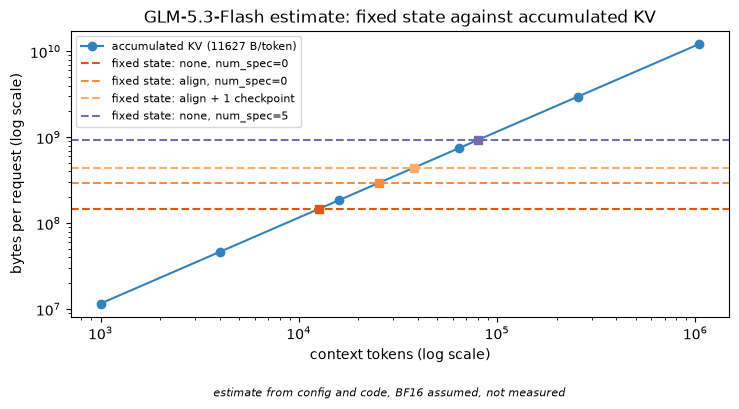

In [26]:
figure, axis = plt.subplots(figsize=(8.5, 4.2))
base = comparison["none, num_spec=0"]
axis.plot(CONTEXTS, [r["accumulated_kv_bytes"] for r in base["rows"]], marker="o", color="#3182bd", label="accumulated KV (11627 B/token)")
for (name, case), color in zip(comparison.items(), ("#e6550d", "#fd8d3c", "#fdae6b", "#756bb1")):
    axis.axhline(case["fixed_bytes_per_request"], color=color, linestyle="--", label=f"fixed state: {name}")
    axis.plot(case["crossover_tokens"], case["fixed_bytes_per_request"], marker="s", color=color)
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel("context tokens (log scale)")
axis.set_ylabel("bytes per request (log scale)")
axis.set_title("GLM-5.3-Flash estimate: fixed state against accumulated KV")
axis.legend(fontsize=8, loc="upper left")
figure.text(0.5, 0.01, "estimate from config and code, BF16 assumed, not measured", ha="center", fontsize=8, style="italic")
figure.subplots_adjust(bottom=0.2)
plt.close(figure)
figure

In [27]:
BLOCK_BY_SCENARIO = {row["scenario"]: row["block_size"] for row in kv.real_scenarios(GLM)}
MLA_ALIGN, MAIN_RECORD_BF16 = 128, 1024  # interface.py의 attn_block_size 식, GLM BF16 main record
kda_rows = []
for row in kv.real_kda_table():
    counted = kv.glm_context_comparison([], num_spec=row["num_spec"], mamba_cache_mode=row["mamba_cache_mode"],
                                        prefill_checkpoint_blocks=row["prefill_checkpoint_blocks"])
    state, page = row["state_bytes_per_rank"], row["page_bytes_per_rank"]
    kda_rows.append({"num_spec": row["num_spec"], "mamba_cache_mode": row["mamba_cache_mode"], "checkpoint": row["prefill_checkpoint_blocks"],
                     "tp_ranks": row["tp_ranks"], "block_size": BLOCK_BY_SCENARIO[row["scenario"]],
                     "block_by_formula": MLA_ALIGN * ceil(state / (MLA_ALIGN * MAIN_RECORD_BF16)),
                     "state_bytes_per_rank": state, "page_bytes_per_rank": page,
                     "resident_states": row["fixed_bytes_padded_per_rank"] // (page * row["layers"]),
                     "fixed_bytes_unpadded_all_ranks": row["fixed_bytes_unpadded_all_ranks"],
                     "fixed_bytes_padded_all_ranks": row["fixed_bytes_padded_all_ranks"],
                     "crossover_real": round(row["crossover_tokens"]), "crossover_estimate": round(counted["crossover_tokens"]),
                     "kind": row["kind"]})
view.table(kda_rows)

,num_spec,mamba_cache_mode,checkpoint,tp_ranks,block_size,block_by_formula,state_bytes_per_rank,page_bytes_per_rank,resident_states,fixed_bytes_unpadded_all_ranks,fixed_bytes_padded_all_ranks,crossover_real,crossover_estimate,kind
0,0,none,0,1,4352,4352,4341760,4456448,1,147619840,151519232,13027,12696,real_class
1,5,none,0,1,4480,4480,4587520,4587520,6,935854080,935854080,80461,80490,real_class
2,0,none,1,1,4352,4352,4341760,4456448,1,147619840,151519232,13027,12696,real_class
3,0,align,0,1,4352,4352,4341760,4456448,2,295239680,303038464,26053,25393,real_class
4,5,align,0,1,4480,4480,4587520,4587520,7,1091829760,1091829760,93872,93905,real_class
5,0,align,1,1,4352,4352,4341760,4456448,3,442859520,454557696,39080,38089,real_class
6,5,align,1,1,4480,4480,4587520,4587520,8,1247805440,1247805440,107282,107320,real_class
7,0,none,0,4,1152,1152,1085440,1179648,1,147619840,160432128,3444,12696,real_class
8,0,align,1,4,1152,1152,1085440,1179648,3,442859520,481296384,10332,38089,real_class


**관찰할 것.** 첫 표의 `crossover_tokens` 칸을 예측과 비교하고, `case` 칸이 달라질 때 어떻게 움직이는지 보세요. 둘째 표의 `fixed_share` 칸이 `context_tokens`를 따라 어떻게 변합니까? 그림에서 네모 표시는 파선과 실선이 만나는 지점입니다. 그림 아래 표는 같은 값의 실제 클래스 실행 기록입니다. `num_spec` 칸이 0인 행과 5인 행에서 `fixed_bytes_unpadded_all_ranks`와 `fixed_bytes_padded_all_ranks`를 비교하세요. `tp_ranks` 칸이 4인 행에서 `crossover_real`과 `crossover_estimate`가 왜 크게 벌어지는지도 생각해 보세요.

어느 행이 실제에 가까운지가 중요합니다. `mamba_cache_mode`([`config/cache.py:189`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/config/cache.py#L189))의 기본값은 `none`이지만 `MambaModelConfig`([`config.py:687`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/config.py#L687))가 prefix caching이 켜져 있으면 `align`으로 바꾸고, `max_memory_usage_bytes`([`kv_cache_interface.py:1076`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L1076))는 그 모드에서 `2 + 추측 block + checkpoint block`벌을 잡습니다. FlashKDA backend면 checkpoint block이 하나 붙습니다(`get_kv_cache_spec`([`glm5next/common/kda.py:174`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/kda.py#L174)), P8-23, P8-24). `none` 모드는 `1 + 추측 block`벌입니다. 그러니 첫 행은 하한입니다. 이 값들도 BF16을 가정한 토큰당 값으로 나눈 것이라 저장 형식이 바뀌면 함께 움직입니다.

**padding까지 넣은 값.** hybrid 모델의 block은 attention page가 KDA page 이상이 되도록 고릅니다. `attn_block_size`([`interface.py:1086`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/interface.py#L1086))의 식은 128 × 올림(state / (128 × 1,024))이고(1,024B는 BF16 main record), 표의 `block_by_formula`가 이 식을 옮긴 값입니다. `block_size`와 비교해 보세요. 그 뒤 KDA page를 attention page와 같게 늘립니다(`mamba_page_size_padded`([`interface.py:1116`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/platforms/interface.py#L1116))). `num_spec` 0이면 state 4,341,760B가 page 4,456,448B가 되어 한 벌 기준 151,519,232B이고, `align`과 checkpoint 1이면 454,557,696B입니다. 교차 문맥은 13,027과 39,080 token입니다. `num_spec` 5이면 state가 4,587,520B로 block 4480의 page와 정확히 같아 padding이 없습니다. 그 대신 state를 6벌 잡으므로 935,854,080B이고 계산 표의 값과 같습니다.

TP4 행은 TP 그룹만 값으로 바꾼 호출이고 실제 4-GPU 실행이 아닙니다. KDA state는 rank마다 나뉘고 MLA record는 rank마다 그대로입니다. 그래서 rank 하나끼리 나눈 교차 문맥이 3,444와 10,332 token으로 작아집니다. 네 rank를 더한 고정 state는 padding 때문에 160,432,128B로 늘어납니다. `crossover_estimate`는 TP를 세지 않는 계산이라 TP1과 같습니다. 이 표의 값도 서버 값이 아니라 클래스 호출 값입니다.

### 꼬리 상태의 크기

5절의 꼬리는 얼마나 클까요. 실제 spec의 행 크기와 행 수로 계산합니다. 창을 감싸는 block 올림은 넣지 않았으므로 아래 값은 하한이고 추정입니다.

In [28]:
TAIL_NAMES = {(V4, "compressor_state", 8): "V4 CSA tail", (V4, "compressor_state", 128): "V4 HCA tail",
              (V4, "indexer_compressor_state", 8): "V4 indexer tail", (V41, "compressor_state", 8): "V4.1 ratio-2 tail",
              (GLM, "tail", 4): "GLM kpool tail"}
tail_results = {model: kv.tail_bytes_per_request(model) for model in (V4, V41, GLM)}
tails = view.table([{"cache": TAIL_NAMES[model, row["cache"], row["rows"]], "rows": row["rows"], "row_bytes": row["row_bytes"],
                     "layers": row["layers"], "spec": row["spec_class"], "bytes_per_layer": row["bytes_per_layer"],
                     "bytes_per_request": row["bytes_per_request"], "kind": result["kind"]}
                    for model, result in tail_results.items() for row in result["rows"]])
display(tails)
view.table([{"model": model, "total_bytes_per_request": result["total_bytes_per_request"], "kind": result["kind"]}
            for model, result in tail_results.items()])

,cache,rows,row_bytes,layers,spec,bytes_per_layer,bytes_per_request,kind
0,V4 CSA tail,8,8192,21,SlidingWindowMLASpec,65536,1376256,estimate
1,V4 HCA tail,128,4096,20,SlidingWindowMLASpec,524288,10485760,estimate
2,V4 indexer tail,8,2048,21,SlidingWindowMLASpec,16384,344064,estimate
3,V4.1 ratio-2 tail,8,4096,3,CircularBufferSpec,32768,98304,estimate
4,GLM kpool tail,4,512,11,CircularBufferSpec,2048,22528,estimate


,model,total_bytes_per_request,kind
0,DeepSeek-V4-Flash,12206080,estimate
1,DeepSeek-V4.1-Flash,98304,estimate
2,GLM-5.3-Flash,22528,estimate


**관찰할 것.** `rows` 칸과 `bytes_per_layer` 칸에서 V4 HCA 행을 읽으세요. 압축률을 크게 올린 층이 꼬리에서는 어떤 값을 치릅니까? `bytes_per_request` 칸에서 V4의 세 행과 V4.1 행도 비교하세요.

표는 `tail_bytes_per_request`가 실제 spec의 행 수와 행 크기를 읽어 곱한 값입니다. 입력은 실제 클래스 실행이고 곱은 이 자료의 추정입니다. V4의 꼬리는 main 압축기(CSA 21층, HCA 20층)에만 있지 않습니다. indexer도 자기 압축기 `self.compressor`([`deepseek_v4/attention.py:1022`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L1022))를 가지므로 8행 × 2,048B × 21층 = 344,064B가 더 붙어, V4 세 행의 합은 12,206,080B입니다(P7-60).

행 수와 행 크기의 근거는 `self.sliding_window`([`deepseek_v4/compressor.py:160`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/compressor.py#L160))(겹침 때문에 CSA는 2m행), `state_dim`([`deepseek_v4/compressor.py:283`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/compressor.py#L283)), `self.block_size`([`deepseek_v41/compressor.py:153`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/compressor.py#L153)), `state_dim`([`deepseek_v41/compressor.py:236`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/compressor.py#L236)), `ring`([`glm5next/common/attention.py:163`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L163))입니다. V4.1은 압축률이 1보다 큰 소유 층에만 이 ring을 둡니다(`compress_ratio > 1`). GLM의 꼬리는 원본 K와 gate score를 BF16으로 담고 `num_speculative_tokens`가 커지면 ring도 커집니다. 표는 0일 때입니다. CSA2가 압축의 겹침을 없앤 것(P7-22)이 꼬리를 줄이는 방향과 같다는 연결은 수업의 해석입니다.

이제 세 모델의 요청당 고정 몫을 나란히 봅니다. SWA는 창 128 × 층 수 × record입니다. 층 수는 config 값이고 record는 `swa_bytes_per_token`([`deepseek_v41/attention.py:513`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L513))와 `DeepseekV4SWACache.get_kv_cache_spec`([`sparse_swa.py:124`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/sparse_swa.py#L124))에서 읽었습니다. 꼬리는 위 표입니다. 모두 block 올림을 뺀 하한이고 추정입니다.

In [29]:
state_none = kv.glm_kda_fixed_state()["fixed_bytes_per_request"]
fixed = [
    {"model": V4, "local_branch": "SWA on 43 layers, 584B record", "local_bytes": 128 * 43 * 584,
     "tail_bytes": tail_results[V4]["total_bytes_per_request"]},
    {"model": V41, "local_branch": "SWA on 40 layers, 528B record", "local_bytes": 128 * 40 * 528,
     "tail_bytes": tail_results[V41]["total_bytes_per_request"]},
    {"model": GLM, "local_branch": "KDA on 34 layers, one state each", "local_bytes": state_none,
     "tail_bytes": tail_results[GLM]["total_bytes_per_request"]},
]
fixed_frame = view.table(fixed)
fixed_frame["fixed_bytes_lower_bound"] = fixed_frame["local_bytes"] + fixed_frame["tail_bytes"]
fixed_frame["kind"] = "estimate"
with pd.option_context("display.max_colwidth", None):
    display(fixed_frame)

,model,local_branch,local_bytes,tail_bytes,fixed_bytes_lower_bound,kind
0,DeepSeek-V4-Flash,"SWA on 43 layers, 584B record",3214336,12206080,15420416,estimate
1,DeepSeek-V4.1-Flash,"SWA on 40 layers, 528B record",2703360,98304,2801664,estimate
2,GLM-5.3-Flash,"KDA on 34 layers, one state each",147619840,22528,147642368,estimate


**관찰할 것.** `fixed_bytes_lower_bound` 칸에서 GLM-5.3-Flash 행과 V4.1-Flash 행의 비를 계산하세요. `local_bytes`와 `tail_bytes` 중 어느 쪽이 그 차이를 만듭니까? V4-Flash 행에서는 어느 쪽이 더 큽니까?

Kimi K3 보고서는 이 비용을 prefix cache 설계의 문제로 씁니다. K3는 3개 KDA 층과 1개 Gated MLA 층을 반복하고, config는 93층에 KDA 69개, 전역 attention 24개입니다. config에 `qk_rope_head_dim` 64가 남아 있는데 보고서는 MLA에 위치 인코딩을 쓰지 않는다고 하므로, 그 값이 실제로 쓰이는지는 확인하지 못했습니다(P7-52). KDA 상태는 큰 스냅샷이라 드문 경계에서만 저장할 수 있고, 블록 해시 방식은 모든 층이 같은 블록 크기를 쓰므로 공유 블록이 1024~6144 token으로 강제된다고 씁니다. 그래서 물리 블록과 해시 블록을 나누고, 적중 경계는 둘 다 만족하는 가장 긴 지점으로 삼습니다(§5.4.1, 제작사 주장, P7-53). vLLM에서는 `get_kv_cache_spec`([`kimi_k3/nvidia/kda.py:835`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/kimi_k3/nvidia/kda.py#L835))이 prefill checkpoint 필드를 `MambaSpec`에 덧붙입니다. idle prefix를 CPU DRAM으로 내릴 때 KDA 상태도 함께 움직입니다(§5.3.1, P7-54). GLM-5.3-Flash의 block 크기는 이제 클래스 호출 값이 있습니다. BF16에서 TP1 4352, TP4 1152, `num_spec` 5에서 4480이고 `fp8`, `fp8_ds_mla`, `nvfp4_ds_mla`에서 8576, SM120 FlashInfer에서 8704입니다(8절 표, `data/reference_specs.json`). TP1과 TP4 값은 vLLM 자체 테스트의 `TP_FLOOR_MANAGER_BLOCKS`([`test_kpool_indexer_block_sizes.py:26`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/tests/v1/attention/test_kpool_indexer_block_sizes.py#L26))에도 있습니다. group 수도 형식마다 달라 6, 5, 7로 움직입니다. 다만 대역 backend로 부른 값이지 서버 값이 아닙니다. 서버의 값은 시작 로그에서 읽는 자리이고(P8-20) 그 로그는 아직 확인하지 못했습니다.

### bounded replay는 근사다

V4에서 SWA 때문에 persistent cache가 거의 절반을 먹었고(arXiv 2609.19969 §3.2.1), 지우면 다시 계산해야 합니다. 정확히 복원하려면 SWA 의존이 층마다 쌓이므로 `L * n_win` token을 다시 돌려야 합니다. V4.1 값으로 40 × 128 = 5,120 token입니다(설정값의 곱, 추정). V4 보고서의 세 전략(전부 저장, 주기적 저장, 저장 안 함)이 이 교환입니다(arXiv 2606.19348 §3.5.2, P7-19).

SWA Bounded Replay는 최근 `n_win`개, 즉 128 token만 다시 돌리고 SWA를 재생 구간으로 자릅니다(arXiv 2609.19969 §3.2.2, P7-28). 보고서는 복원된 상태가 근사이고 적중 위치에 따라 결과가 수학적으로 동일하지 않다고 스스로 씁니다. 품질 영향이 미미하다는 것은 제작사 주장입니다. persistent KV가 V4의 약 1/8이라는 값은 SWA를 뺀 약 절반과 global KV의 약 1/4을 곱한 것이고(제작사 주장, P7-27), 8절의 계산은 이 중 1/4 쪽만 다룹니다.

코드에서 이 옵션은 `prefix_cacheable`([`kv_cache_interface.py:969`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L969))를 거짓으로 만들고 `prefix_replay_tokens`([`kv_cache_interface.py:973`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L973))를 창 크기로 만듭니다. SWA는 prefix caching 대상에서 빠지고 적중 뒤 창만큼 다시 계산합니다.

### FP4는 서버 플래그가 아니라 학습의 결과다

V4.1 main KV의 FP4는 post-training에서 양자화 인지 학습(QAT)으로 모델을 적응시킨 뒤의 형식입니다(arXiv 2609.19969 §2.4.4, P7-25). 형식 선택도 값의 범위를 이 모델로 따져 정했습니다. 그러므로 다른 모델의 KV에 같은 형식을 적용해도 같은 품질이 나온다는 근거가 이 자료에는 없습니다. SWA KV가 FP8로 남은 것도 민감도 때문입니다. 하드웨어 조건은 8절의 SM100 검사입니다.

### top-k의 한계

읽는 항목 수를 묶는 것이 이득이자 한계입니다. 1M 문맥에서 질의 하나가 얼마나 읽는지 세어 봅니다.

In [30]:
TOPK_V4, TOPK_V41, TOPK_GLM = FIELDS[V4]["index_topk"], FIELDS[V41]["index_topk"], FIELDS[GLM]["index_topk"]
KPOOL = FIELDS[GLM]["index_kpool"]
sparse_rows = [
    {"layer_kind": "V4 CSA, ratio 4", "selected": TOPK_V4, "entries_at_1M": CONTEXT_1M // 4, "all_selected_up_to_tokens": "-"},
    {"layer_kind": "V4.1 encoder, ratio 2", "selected": TOPK_V41, "entries_at_1M": CONTEXT_1M // 2, "all_selected_up_to_tokens": (TOPK_V41 + 1) * 2 - 1},
    {"layer_kind": "V4.1 decoder, ratio 1", "selected": TOPK_V41, "entries_at_1M": CONTEXT_1M, "all_selected_up_to_tokens": (TOPK_V41 + 1) * 1 - 1},
    {"layer_kind": "GLM sparse, pools of 4", "selected": TOPK_GLM // KPOOL, "entries_at_1M": CONTEXT_1M // KPOOL, "all_selected_up_to_tokens": "-"},
]
frame = view.table(sparse_rows)
frame["read_share_percent"] = (100 * frame["selected"] / frame["entries_at_1M"]).round(3)
frame["kind"] = "estimate"
frame

,layer_kind,selected,entries_at_1M,all_selected_up_to_tokens,read_share_percent,kind
0,"V4 CSA, ratio 4",512,262144,-,0.195,estimate
1,"V4.1 encoder, ratio 2",512,524288,1025,0.098,estimate
2,"V4.1 decoder, ratio 1",512,1048576,512,0.049,estimate
3,"GLM sparse, pools of 4",512,262144,-,0.195,estimate


**관찰할 것.** `read_share_percent` 칸은 1M 문맥에서 질의 하나가 읽는 몫입니다. 어느 행이 가장 적게 읽습니까? `selected`는 V4.1과 V4에서 압축 항목, GLM에서 pool입니다. `all_selected_up_to_tokens` 칸은 뒤 문단에서 설명합니다.

비용은 네 가지입니다.

- **안 뽑힌 것은 못 봅니다.** 점수가 틀리면 그 질의는 그 항목을 볼 수 없습니다. GLM-5 논문(arXiv 2602.15763 §2.1.2)은 DSA가 구조상 손실이 없고(lossless by construction) 품질 저하도 없다고 쓰지만(P7-35), 이것은 제작사 주장입니다.
- **indexer 자체는 남습니다.** 전체를 훑는 비용이 `O(L^2)`로 남고(P7-10), V4.1에서도 첫 Full 층의 훑기는 남습니다(P7-24).
- **Reuse 층은 앞 층의 선택을 그대로 씁니다.** 그 층 자신의 query로 다시 고르지 않습니다(P7-21).
- **짧은 문맥에서는 sparse가 아닙니다.** 짧은 문맥 분기([`deepseek_v41/attention.py:1483`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L1483))는 압축 항목 수가 top-k 이하면 후보를 모두 고릅니다. `all_selected_up_to_tokens`는 이 식의 경계입니다. 이 분기는 V4.1 코드만 확인했습니다.

최근 token은 별도로 챙깁니다. V4 계열은 SWA 가지로(P7-15), GLM은 `index_kpool_always_select_tail`이 참이어서 미완성 꼬리를 항상 포함합니다(P7-43).

## 10. GLM-5.3-Flash와 V4.1-Flash 나란히

두 모델은 같은 질문에 다른 답을 냅니다. 표의 숫자는 앞 절에서 계산한 값을 다시 불렀습니다.

In [31]:
glm_rows, v41_rows = ROLE_ROWS[GLM], ROLE_ROWS[V41]
glm_total, v41_total = glm["total_bytes_per_token"], results[V41]["total_bytes_per_token"]
fixed_by_model = fixed_frame.set_index("model")["fixed_bytes_lower_bound"]
at_1m = lambda per_token, fixed_bytes: round((per_token * CONTEXT_1M + fixed_bytes) / 2**30, 2)
side = [
    ("layers (config)", 45, 40),
    ("layers owning main KV (config)", sum(r["main_record_bytes"] > 0 for r in glm_rows), sum(r["main_record_bytes"] > 0 for r in v41_rows)),
    ("layers reading global KV (config)", sum(r["role"] == "sparse_mla" for r in glm_rows), sum(r["compress_ratio"] > 0 for r in v41_rows)),
    ("main KV tokens per state (config)", "1 on all owners", "2, 2, 2, 1"),
    ("indexer K tokens per state (config)", f"{KPOOL} (kpool)", "same as main KV"),
    ("main record bytes (assumption)", "1024 BF16 assumed", "288 nvfp4_ds_mla"),
    ("local branch (config)", "KDA state on 34 layers", "SWA on 40 layers"),
    ("top-k (config)", f"{TOPK_GLM} tokens as {TOPK_GLM // KPOOL} pools", f"{TOPK_V41} entries"),
    ("global KV bytes per token", f"{glm_total:,.0f} (estimate)", f"{v41_total:,.0f} (reproduced)"),
    ("real pool bytes per token (class call)", f"{kv.real_stride(GLM)['bytes_per_token']:,.2f} (real_class)", f"{kv.real_stride(V41)['bytes_per_token']:,.2f} (real_class)"),
    ("fixed bytes per request, lower bound", f"{fixed_by_model[GLM]:,} (estimate)", f"{fixed_by_model[V41]:,} (estimate)"),
    ("crossover: fixed = accumulated KV, tokens", f"{fixed_by_model[GLM] / glm_total:,.0f} (estimate)", f"{fixed_by_model[V41] / v41_total:,.0f} (estimate)"),
    ("one request at 1M context, GiB", f"{at_1m(glm_total, fixed_by_model[GLM])} (estimate)", f"{at_1m(v41_total, fixed_by_model[V41])} (estimate)"),
    ("vendor technical report", "not found (미확인)", "arXiv 2609.19969"),
]
with pd.option_context("display.max_colwidth", None):
    display(view.table([{"item": item, GLM: a, V41: b} for item, a, b in side]))

,item,GLM-5.3-Flash,DeepSeek-V4.1-Flash
0,layers (config),45,40
1,layers owning main KV (config),11,4
2,layers reading global KV (config),11,38
3,main KV tokens per state (config),1 on all owners,"2, 2, 2, 1"
4,indexer K tokens per state (config),4 (kpool),same as main KV
5,main record bytes (assumption),1024 BF16 assumed,288 nvfp4_ds_mla
6,local branch (config),KDA state on 34 layers,SWA on 40 layers
7,top-k (config),2048 tokens as 512 pools,512 entries
8,global KV bytes per token,"11,627 (estimate)",890 (reproduced)
9,real pool bytes per token (class call),"11,631.53 (real_class)",896.00 (real_class)


**관찰할 것.** `item` 칸의 `layers owning main KV (config)`, `main KV tokens per state (config)`, `main record bytes (assumption)` 세 행을 읽으세요. 8절 막대에서 main KV 몫의 차이는 이 셋으로 설명됩니다. `one request at 1M context, GiB` 행의 GLM 값은 BF16을 가정한 값이라 V4.1과 저장 형식이 다릅니다. 그대로 비교하지 않습니다. `crossover: fixed = accumulated KV, tokens` 행에서 두 모델의 차이도 읽으세요. 이 행의 GLM 값이 9절 표의 첫 행과 조금 다른 것은 여기서 꼬리를 더했기 때문입니다.

**공통점.** 둘 다 지역과 전역을 나눕니다. [Z.ai GLM-5.3-Flash 문서](https://docs.z.ai/guides/vlm/glm-5.3-flash)는 선형 attention이 지역 의존성을, sparse attention이 전역 문맥을 맡는다고 씁니다. V4.1 보고서 §1은 V4를 SWA 기반 지역 처리 뼈대에 압축된 전역 문맥을 더한 것으로 보고 전역 가지를 단순화했다고 씁니다.

**다른 점.**

| 질문 | GLM-5.3-Flash | V4.1-Flash |
|---|---|---|
| 지역 정보를 어디 두나 | 층을 KDA로 바꾸어 요청당 고정 state로 | 모든 층의 SWA KV로. 창에 묶이지만 층마다 있음 |
| 전역 정보를 어떻게 줄이나 | sparse 층만 남기고, 그 층의 main KV는 token마다 유지. indexer K만 4개를 하나로 | 소유 층만 남기고 나머지는 공유. 압축률 2, FP4 |
| 치르는 값 | 큰 고정 state, 저장된 경계에서만 적중(P8-23) | 근사 복원, 새 학습 방식(QAT), 하드웨어 조건 |

**왜 이렇게 설계했나.** 확인되는 이유는 일부입니다. GLM-5 논문(arXiv 2602.15763 §2.1.2)은 GLM-9B를 64K로 이어 학습하며 층 절반을 효율 층으로 바꾼 실험(표 5)에서 SWA를 단순히 번갈아 넣으면 RULER 128K가 75.28에서 44.93으로 떨어진다는 결과를 들어 DSA를 택했다고 씁니다(제작사 주장, P7-35). Z.ai는 GLM-5.3-Flash의 KV가 Kimi-K3와 DeepSeek-V4-Flash보다 아직 약간 크다고 스스로 씁니다(층당 평균, BF16, 제작사 주장, P7-46). 이 체크포인트가 main KV를 압축하지 않은 이유는 문서에 없습니다(P7-48, 미확인). 전 위치를 읽을 수 있게 남겨 sparse 선택의 손실을 줄이는 대신 저장을 치렀다는 것은 수업의 해석입니다. 어느 모델이 더 좋은지는 이 노트북으로 말할 수 없습니다. 품질을 측정하지 않았고, 표의 숫자는 비용 쪽만 봅니다.

## 11. vLLM은 이것을 어떻게 표현하나

논문의 말은 코드에서 몇 개의 spec 클래스로 줄어듭니다. 각 층이 `get_kv_cache_spec()`으로 밝히는 값은 `02b`의 group과 manager가 받는 입력입니다(P7-59~P7-62).

| 원문의 말 | spec | `tokens_per_state` | 문맥과의 관계 | 코드 |
|---|---|---|---|---|
| V3.2 main KV | `MLAAttentionSpec` | 1 | 비례 | [`mla_attention.py:1350`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/layers/attention/mla_attention.py#L1350) |
| V3.2 indexer K | `MLAAttentionSpec` | 1 | 비례 | [`deepseek_v2.py:638`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/deepseek_v2.py#L638) |
| V4 CSA, HCA 압축 KV | `MLAAttentionSpec` | 압축률 4, 128 | 비례, 압축률로 나눔 | [`deepseek_v4/attention.py:871`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L871) |
| V4 indexer K | `MLAAttentionSpec` | 압축률 4 | 비례 | [`deepseek_v4/attention.py:882`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/attention.py#L882) |
| V4, V4.1 SWA KV | `SlidingWindowMLASpec` | 1 | 창에 묶임 | [`sparse_swa.py:124`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/sparse_swa.py#L124) |
| V4 압축 꼬리 | `SlidingWindowMLASpec` | 1 | 창에 묶임 | [`deepseek_v4/compressor.py:184`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/compressor.py#L184) |
| V4.1 압축 KV | `MLAAttentionSpec`, 소유 층만 | 압축률 2, 1 | 비례 | [`deepseek_v41/attention.py:1143`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L1143) |
| V4.1 indexer K | `MLAAttentionSpec`, 소유 층만 | 압축률 2, 1 | 비례 | [`deepseek_v41/attention.py:1220`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/attention.py#L1220) |
| V4.1 압축 꼬리 | `CircularBufferSpec` | 1 | 요청당 block 하나 | [`deepseek_v41/compressor.py:161`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/compressor.py#L161) |
| GLM KDA 층 | `MambaSpec` | -1 | 없음 | [`glm5next/common/kda.py:163`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/kda.py#L163) |
| GLM sparse main KV | `MLAAttentionSpec` | 1 | 비례 | [`glm5next/common/attention.py:385`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L385) |
| GLM indexer K | `MLAAttentionSpec` | `index_kpool` | 비례, 4로 나눔 | [`glm5next/common/attention.py:119`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L119) |
| GLM kpool 꼬리 | `CircularBufferSpec` | 1 | 요청당 block 하나 | [`glm5next/common/attention.py:170`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L170) |
| K3 KDA 층 | `MambaSpec` + checkpoint 필드 | -1 | 없음 | [`kimi_k3/nvidia/kda.py:829`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/kimi_k3/nvidia/kda.py#L829) |
| K3 MLA 층 | `MLAAttentionSpec` | 1 | 비례 | [`kimi_k3/nvidia/mla.py:417`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/kimi_k3/nvidia/mla.py#L417) |

세 가지를 짚어 둡니다.

- `tokens_per_state`([`kv_cache_interface.py:528`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L528))의 주석이 압축을 직접 적습니다. 값이 N이면 record 하나가 token N개를 덮고, `get_num_kernel_states`([`kv_cache_interface.py:231`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L231))가 block 안 상태 수를 `block_size // N`으로 계산합니다(P7-59). `tokens_per_state`([`kv_cache_interface.py:1045`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L1045))의 -1은 token 단위가 아니라는 표시이고 그때 상태 수는 1입니다.
- `head_size_v`([`kv_cache_interface.py:698`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L698))가 0인 것이 MLA에 2배 항이 없는 이유입니다. 잠재 벡터 하나뿐입니다(P7-04, P7-59).
- V4 꼬리가 `SlidingWindowMLASpec`에서 V4.1의 `CircularBufferSpec`으로 바뀌었습니다(P7-61). V4.1의 `get_kv_cache_spec`([`deepseek_v41/compressor.py:161`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v41/compressor.py#L161)), GLM의 `get_kv_cache_spec`([`glm5next/common/attention.py:170`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/glm5next/common/attention.py#L170))이 그 자리입니다. `CircularBufferSpec`([`kv_cache_interface.py:909`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L909))은 프롬프트 재사용 대상이 아니라 살아 있는 묶음을 담는 ring입니다.

### 문서와 코드가 다를 때

| 문서가 말하는 것 | 코드가 말하는 것 | 근거 |
|---|---|---|
| Kimi Linear §1은 KDA kernel이 캐시와 스케줄링 인터페이스를 고칠 필요가 없다고 씁니다 | vLLM v0.32.0은 `MambaSpec`과 hybrid KV cache manager를 거칩니다. 논문의 주장으로만 읽습니다. 코드가 맞습니다 | P7-51, `MambaSpec`([`kv_cache_interface.py:1035`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/kv_cache_interface.py#L1035)) |
| V4 보고서 그림 6은 상태 캐시 한 block에 SWA와 꼬리를 함께 담습니다 | vLLM은 둘을 별도 spec으로 등록하고 hybrid manager가 group으로 묶습니다. 대응하지만 같지 않습니다. 코드가 맞습니다 | P7-63, `DeepseekV4SWACache.get_kv_cache_spec`([`sparse_swa.py:124`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/v1/attention/backends/mla/sparse_swa.py#L124)), `get_kv_cache_spec`([`deepseek_v4/compressor.py:184`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/compressor.py#L184)) |
| transformers `configuration_glm5_next.py`의 설명은 `index_kpool` 기본값을 16으로 적습니다 | 이 체크포인트의 config 값은 4입니다. 계산에는 config 값을 씁니다. 체크포인트가 맞습니다 | P7-45, P7-43 |
| vLLM `index_cache.md`는 `use_index_cache`를 참으로 두어야 켜진다고 적습니다 | 이 코드 경로는 `index_topk_freq`와 `index_topk_pattern`을 곧바로 읽습니다. `use_index_cache`는 `minimax_m3`에서만 읽습니다. 코드가 맞습니다 | [`index_cache.md:24`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/docs/features/index_cache.md#L24), [`deepseek_v2.py:1152`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/model_executor/models/deepseek_v2.py#L1152) |

## 직접 해보기

값을 하나만 바꿉니다. 바꾸기 전에 결과를 먼저 적으세요. 기본값 그대로 실행해도 오류가 나지 않습니다.

### 해보기 1

V4.1의 main record를 바꿉니다. `MAIN_RECORD`를 288에서 528로 바꾸면 합이 얼마가 될까요? `INDEXER_RECORD`를 68에서 132로 바꾸는 쪽과 어느 쪽 영향이 큽니까? 왜 그런지 가중치로 설명하세요.

In [32]:
MAIN_RECORD = 288
INDEXER_RECORD = 68
print("V4.1 토큰당 global KV (추정):", reweigh(V41, MAIN_RECORD, INDEXER_RECORD))

V4.1 토큰당 global KV (추정): 890.0


### 해보기 2

draft token 수를 늘립니다. `NUM_SPEC`을 0에서 3으로 바꾸면(9절 표에 없는 값이니 식으로 먼저 계산하세요) `conv_bytes_per_state`, `resident_states`, `fixed_bytes_per_request`, `crossover_tokens`는 각각 어떻게 됩니까? `MODE`를 `"align"`으로 바꾸면요? 한 번에 하나만 바꾸세요.

In [33]:
NUM_SPEC = 0
MODE = "none"
trial = kv.glm_kda_fixed_state(num_spec=NUM_SPEC, mamba_cache_mode=MODE)
trial_compare = kv.glm_context_comparison([CONTEXT_1M], num_spec=NUM_SPEC, mamba_cache_mode=MODE)
view.table([{"conv_bytes_per_state": trial["conv_bytes_per_state"], "resident_states": trial["resident_states"],
             "fixed_bytes_per_request": trial["fixed_bytes_per_request"], "crossover_tokens": round(trial_compare["crossover_tokens"]),
             "kind": trial["kind"]}])

,conv_bytes_per_state,resident_states,fixed_bytes_per_request,crossover_tokens,kind
0,147456,1,147619840,12696,estimate


### 해보기 3

V4의 block 크기를 바꿉니다. 기본값 256은 backend가 선언한 값입니다. 출력을 compressor의 block 주석([`deepseek_v4/compressor.py:164`](https://github.com/vllm-project/vllm/blob/5df63a7203cdb9328d824a27b682e77c7b9928be/vllm/models/deepseek_v4/compressor.py#L164))이 예로 드는 `[256//4, head_dim]`과 맞춰 보세요. `TRY_BLOCK`을 보고서의 128로 바꾸면 `states_in_block`은 어떻게 됩니까? 192로 바꾸면 어떤 행이 어떻게 깨집니까?

In [34]:
TRY_BLOCK = 256
block_contents(TRY_BLOCK)

,block_tokens,layer,cache,tokens_per_state,states_in_block,record_bytes,bytes_in_block,kind
0,256,CSA layer,main,4,64,584,37376,estimate
1,256,CSA layer,indexer,4,64,68,4352,estimate
2,256,HCA layer,main,128,2,584,1168,estimate


## 확인 질문

답은 노트북에 없습니다. 자기 말로 적고, 근거가 되는 코드 줄이나 논문 절을 함께 대세요.

1. IndexShare를 켜면 KV가 얼마나 줄어듭니까? "2.9배"라고 답하면 왜 틀립니까?
2. FP4 main KV가 attention 행렬곱을 빠르게 하지 않는데도 쓰는 이유는 무엇입니까?
3. CSA, HCA, kpool에 꼬리 상태가 필요한 이유는 무엇입니까? prefix 적중 때 꼬리는 어떻게 됩니까?
4. V4.1의 890이 `reproduced`라는 말은 어디까지입니까? 어떤 설정이 바뀌면 다른 값이 됩니까?
5. KDA 고정 state가 쌓인 KV보다 커지는 경우와 작아지는 경우를 문맥 길이로 말하세요. prefix caching을 켜면 어떻게 달라집니까?
6. CSA2의 Reindex 층과 Reuse 층은 각각 무엇을 재사용하고 무엇을 자기 층에서 계산합니까? config의 어느 필드로 구분합니까?
7. CED에서 prefill이 절반이 되는 조건은 무엇이고, vLLM에서 꺼지는 경우는 무엇입니까?
8. GLM-5.3-Flash와 V4.1-Flash의 토큰당 값을 그대로 비교하면 왜 안 됩니까?
9. V4의 제작사 값, record 합, 실제 stride는 각각 무엇을 말합니까? 실제 stride를 서버 측정값이라고 부르면 왜 틀립니까?

## 블로그 함께 읽기

「Inside vLLM: 서버 시작부터 KV cache까지 소스 코드 톺아보기」, Jongsu Liam Kim, https://blog.liam.kim/posts/2026/10/Inside-vLLM/ (절 제목으로만 참조합니다).

| 블로그 절 | 읽을 때 볼 점 |
|---|---|
| 8. 여러 종류의 attention: KV cache group과 타입별 manager | 모델별 구성을 짧게 소개합니다. 이 노트북의 층 수, record 크기, 비용은 논문과 config, 코드에서 왔고 블로그를 근거로 쓰지 않았습니다 |

## 정리

- 긴 문맥 에이전트에서는 저장과 전송이 병목이 되었고, 그래서 토큰당 global KV가 세대를 비교하는 지표가 되었습니다. 세대 그림의 값은 제작사 주장입니다.
- 토큰당 global KV는 캐시를 가진 층마다 record 바이트를 `tokens_per_state`로 나눠 더한 값입니다. 항목, sequence, 층의 세 차원이 이 식의 세 자리입니다.
- 저장을 줄이는 것과 연산을 줄이는 것은 다릅니다. top-k, IndexShare, IndexCache, CED는 연산을 줄이고(건너뛴 층의 indexer K는 작은 예외입니다, 4절), MLA, FP4, 압축, 층 공유, 층 교체는 저장입니다. FP4 main KV는 저장만 줄입니다.
- 압축하면 꼬리가 생깁니다. 꼬리와 SWA는 문맥 길이를 따라 늘지 않는 요청당 몫입니다. prefix 재사용 규칙은 모델과 설정에 따라 다릅니다.
- V4.1과 V4의 제작사 값은 층 구성과 record 크기로 재현되지만 그 저장 형식에서만 그렇습니다. GLM-5.3-Flash 값은 추정입니다.
- record 합이 제작사 값과 맞아도 실제 pool은 padding만큼 더 큽니다. 토큰당 V4.1 890은 896, V4 3,514.25는 3,584.25, GLM-5.3-Flash 11,627은 11,631.53입니다. 실제 클래스 호출 값이고 서버 값은 아닙니다.
- 고정 state는 저절로 작지 않고, bounded replay는 근사이며, FP4는 학습의 결과이고, top-k는 안 뽑힌 것을 볼 수 없습니다.
- vLLM은 이 구조를 `MLAAttentionSpec`, `SlidingWindowMLASpec`, `CircularBufferSpec`, `MambaSpec`과 `tokens_per_state`로 표현합니다.

다음 노트북 `03`으로 넘기는 것: 토큰당 바이트와 요청당 고정 state. `03`은 scheduler가 예산을 나누는 규칙과 지표를 읽습니다. 이 두 값을 GPU 메모리 예산에 넣어 동시에 몇 token을 품는지 계산하는 일은 `04b`에서 합니다.

## 참고한 근거

근거 대장(`docs/sources/`)의 파일은 `part2.md`, `part7.md`, `part8.md`입니다.

- `part2.md`: P2-61, P2-62
- `part7.md`: P7-01, P7-02, P7-03, P7-04, P7-05, P7-06, P7-07, P7-08, P7-09, P7-10, P7-11, P7-12, P7-13, P7-14, P7-15, P7-16, P7-17, P7-18, P7-19, P7-20, P7-21, P7-22, P7-23, P7-24, P7-25, P7-26, P7-27, P7-28, P7-29, P7-30, P7-31, P7-32, P7-33, P7-34, P7-35, P7-38, P7-39, P7-40, P7-41, P7-42, P7-43, P7-44, P7-45, P7-46, P7-47(미확인), P7-48(미확인), P7-49, P7-50, P7-51, P7-52, P7-53, P7-54, P7-55, P7-56, P7-57, P7-58, P7-59, P7-60, P7-61, P7-62, P7-63
- `part8.md`: P8-20, P8-23, P8-24

논문과 문서: arXiv 2405.04434(DeepSeek-V2), DeepSeek-V3.2-Exp 보고서, arXiv 2606.19348(DeepSeek-V4), arXiv 2609.19969(DeepSeek-V4.1-Flash), arXiv 2602.15763(GLM-5), arXiv 2510.26692(Kimi Linear), arXiv 2603.12201(IndexCache), Kimi K3 기술 보고서, [GLM-5.2 글](https://huggingface.co/blog/zai-org/glm-52-blog), [Z.ai GLM-5.3-Flash 문서](https://docs.z.ai/guides/vlm/glm-5.3-flash).

실제 클래스 실행 기록: `data/reference_specs.json`, 조건과 한계는 `docs/reference/specs.md`.

config 스냅샷: `data/model_configs.json`(2026-11-02에 받음). 숫자 표기는 0절의 표를 따릅니다.